# NGRC confidence estimation: Lorenz-63 study (notebook version)

This notebook is a self-contained version of the Lorenz-63 pipeline from
[Mesbin/Confidence-estimation-in-NGRC](https://github.com/Mesbin/Confidence-estimation-in-NGRC)
(Modules 1–8), followed by checks from the review and a corrected version of the experiment.

| Part | What it does |
|---|---|
| **A. Original pipeline (re-implemented)** | The repo's Modules 1–8 rewritten in one place; same numbers, Module 8 crash fixed. The unmodified run is in `NGRC_Lorenz_asis_reproduction.ipynb`. |
| **B. Review checks** | Tests *why* the original result is so high: the unstable solver, reused data, autocorrelated statistics. |
| **C. Corrected experiment** | A stable readout, separate data segments, and free-running forecasts, where errors genuinely grow and vary. Asks whether the reservoir state predicts that real error. |
| **D. Summary** | All key numbers from this run in one table. |

Cells marked **Review note** explain findings in plain language.

**Requirements:** `numpy`, `scipy`, `pandas`, `scikit-learn`, `matplotlib`. Runs in about 1–2 minutes on a laptop.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations_with_replacement
from scipy.integrate import solve_ivp
from scipy.stats import pearsonr, spearmanr, ttest_rel, wilcoxon
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8980"
SUMMARY = {}   # collects key numbers for Part D

In [58]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

---
## Part A: Original pipeline, re-implemented (Modules 1–8)

*This re-implements the repo's steps in one place and gives the same numbers, with the Module 8 crash fixed and some plots omitted. For an unmodified run of the GitHub files, see `NGRC_Lorenz_asis_reproduction.ipynb`.*

### A1. Simulate Lorenz-63 (Module 1)
σ = 10, ρ = 28, β = 8/3, from [1, 1, 1], Runge–Kutta 4(5) with tolerance 10⁻⁹, Δt = 0.01 for 100 time units → 10,000 samples.

In [2]:
def lorenz(t, u, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = u
    return [sigma*(y - x), x*(rho - z) - y, x*y - beta*z]

dt, total_time = 0.01, 100
t_eval = np.arange(0, total_time, dt)
sol = solve_ivp(lorenz, (0, total_time), [1.0, 1.0, 1.0], t_eval=t_eval,
                method="RK45", rtol=1e-9, atol=1e-9)
data = np.column_stack((sol.t, *sol.y))          # columns: time, x, y, z
print("Dataset shape:", data.shape)

Dataset shape: (10000, 4)


In [3]:
data.T[:][1].shape

(10000,)

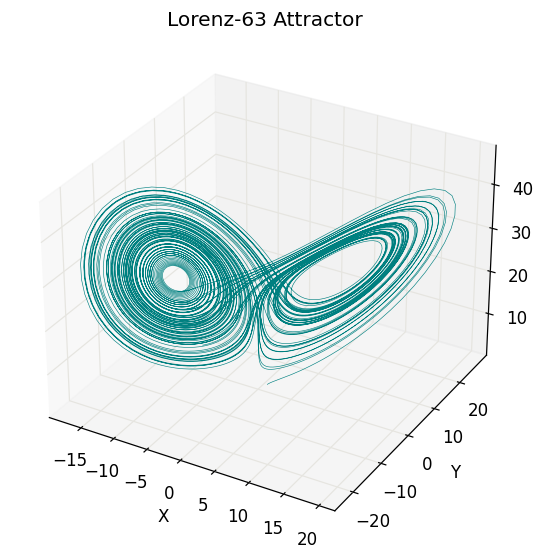

In [4]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')
ax.plot(data.T[:][1], data.T[:][2], data.T[:][3], linewidth=0.4, color="teal")
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_title("Lorenz-63 Attractor")
# plt.savefig(filename)
plt.show()
plt.close()

### A2. Build the NGRC reservoir (Module 2)
Delay embedding with k = 2, s = 1: each row is [x, y, z at t] and [x, y, z at t−1] (6 linear terms), plus all 21 pairwise products and a constant → **28 features**.

In [5]:
k, s = 2, 1
X_state = data[:, 1:]
start = k * s
linear = np.array([np.concatenate([X_state[i - j*s] for j in range(k)])
                   for i in range(start, len(X_state))])
quad_idx = list(combinations_with_replacement(range(linear.shape[1]), 2))
quadratic = np.stack([linear[:, i]*linear[:, j] for i, j in quad_idx], axis=1)
reservoir_full = np.hstack((np.ones((len(linear), 1)), linear, quadratic))

base = ["x(t)", "y(t)", "z(t)", "x(t-1)", "y(t-1)", "z(t-1)"]
feature_names = ["const"] + base + [f"{base[i]}²" if i == j else f"{base[i]}·{base[j]}"
                                    for i, j in quad_idx]
print("Reservoir shape:", reservoir_full.shape)

Reservoir shape: (9998, 28)


### A3. Train the ridge readout (Module 3)
Predict the next state from the reservoir, using the formula in the repo: W = Y Oᵀ (O Oᵀ + αI)⁻¹ with α = 2.5 × 10⁻⁶.
Note that it is trained on **all** samples.

In [6]:
target = data[start + 1:, 1:]                     # next state
reservoir = reservoir_full[:len(target)]
O, Y = reservoir.T, target.T
alpha_readout = 2.5e-6
Wout = (Y @ O.T) @ np.linalg.inv(O @ O.T + alpha_readout*np.identity(O.shape[0]))
print("Wout shape:", Wout.shape, "| trained on", reservoir.shape[0], "samples (all of them)")

Wout shape: (3, 28) | trained on 9997 samples (all of them)


### A4. Baseline prediction error (Module 4)

Prediction RMSE: 0.1637   MAE: 0.1038


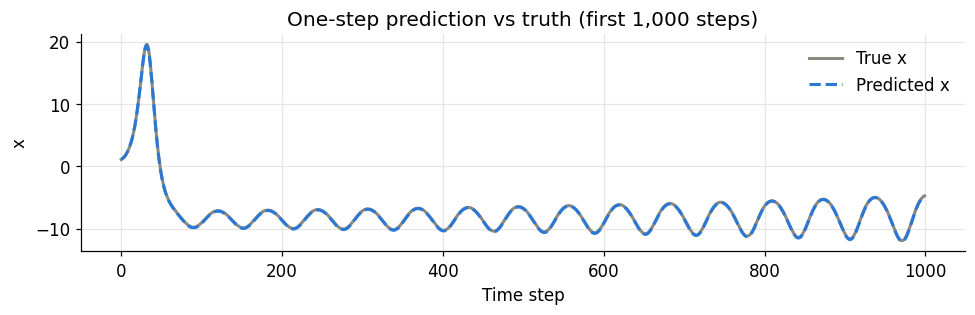

In [7]:
prediction = (Wout @ reservoir.T).T
error_vec = np.abs(target - prediction)
rmse_pred = np.sqrt(np.mean((prediction - target)**2))
print(f"Prediction RMSE: {rmse_pred:.4f}   MAE: {error_vec.mean():.4f}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(target[:1000, 0], color=GREY, label="True x")
ax.plot(prediction[:1000, 0], "--", color=BLUE, label="Predicted x")
ax.set_xlabel("Time step"); ax.set_ylabel("x"); ax.legend(loc="upper right")
ax.set_title("One-step prediction vs truth (first 1,000 steps)")
plt.tight_layout(); plt.show()

### A5. Reference confidence (Module 5)
e(t) = mean over x, y, z of |true − predicted|;  C(t) = 1 / (1 + e(t)).

In [8]:
error = error_vec.mean(axis=1)
C = 1.0 / (1.0 + error)
print(f"Confidence: mean {C.mean():.4f}, min {C.min():.4f}, max {C.max():.4f}")

Confidence: mean 0.9115, min 0.6469, max 0.9986


### A6. Feature selection on the training 80% (Module 6)
Keep features with |Pearson r| ≥ 0.30, p < 0.05 **and** mutual information ≥ the median (the paper mentions only the first two).

In [37]:
n = len(C); n_train = int(0.8*n)
R_tr, C_tr = reservoir[:n_train], C[:n_train]
pear = [pearsonr(R_tr[:, i], C_tr) if R_tr[:, i].std() > 0 else (0.0, 1.0)
        for i in range(R_tr.shape[1])]
mi = mutual_info_regression(R_tr, C_tr, random_state=0)
ranking = pd.DataFrame({"Index": np.arange(R_tr.shape[1]), "Feature": feature_names,
                        "Pearson": [p[0] for p in pear], "Pearson_p": [p[1] for p in pear],
                        "MI": mi})
ranking = ranking.reindex(ranking["Pearson"].abs().sort_values(ascending=False).index).reset_index(drop=True)
mask = (ranking["Pearson"].abs() >= 0.30) & (ranking["Pearson_p"] < 0.05) & (ranking["MI"] >= np.median(ranking["MI"]))
selected_idx = ranking.loc[mask, "Index"].astype(int).tolist()
print(f"Selected {len(selected_idx)} of {reservoir.shape[1]} features:")
display(ranking.loc[mask, ["Feature", "Pearson", "Pearson_p", "MI"]].round(4))

Selected 4 of 28 features:


,Feature,Pearson,Pearson_p,MI
0,x(t-1)²,-0.9906,0,2.51
1,x(t)·x(t-1),-0.9897,0,2.346
2,x(t)²,-0.9855,0,1.878
3,x(t-1)·y(t-1),-0.8632,0,0.8449


### A7. Confidence estimator (Module 7)
Ridge (α = 10⁻³) from the selected features to C, trained on the first 80%, tested on the last 20%.

{'RMSE': 0.007105, 'MAE': 0.005355, 'R2': 0.990269, 'Pearson_r': 0.995134}


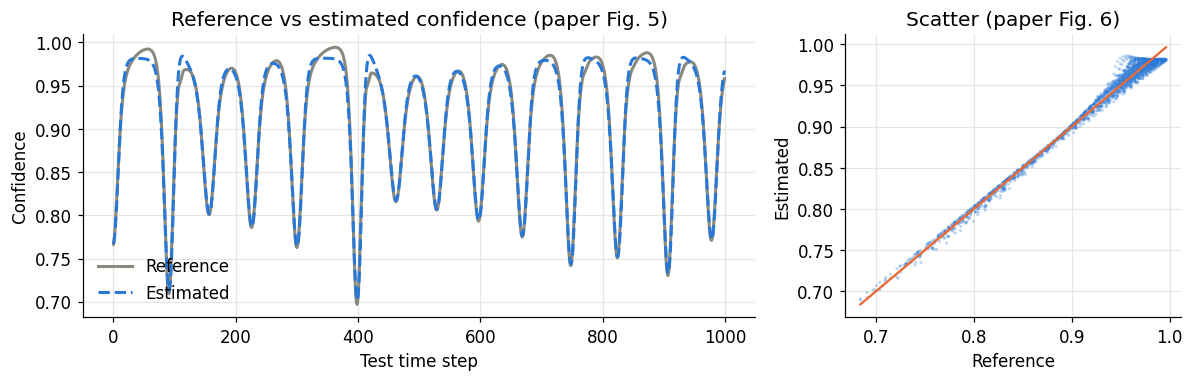

In [11]:
def evaluate(c_true, c_hat):
    return {"RMSE": np.sqrt(mean_squared_error(c_true, c_hat)), "MAE": mean_absolute_error(c_true, c_hat),
            "R2": r2_score(c_true, c_hat), "Pearson_r": pearsonr(c_true, c_hat)[0]}

def split(X, y, f=0.8):
    m = int(len(X)*f); return X[:m], X[m:], y[:m], y[m:]

S = reservoir[:, selected_idx]
S_tr, S_te, C_tr, C_te = split(S, C)
est = Ridge(alpha=1e-3).fit(S_tr, C_tr)
C_hat = est.predict(S_te)
m_orig = evaluate(C_te, C_hat)
print({k: round(v, 6) for k, v in m_orig.items()})
SUMMARY["A. Original estimator R² (paper: 0.9988)"] = m_orig["R2"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(C_te[:1000], color=GREY, label="Reference")
axes[0].plot(C_hat[:1000], "--", color=BLUE, label="Estimated")
axes[0].set_xlabel("Test time step"); axes[0].set_ylabel("Confidence"); axes[0].legend()
axes[0].set_title("Reference vs estimated confidence (paper Fig. 5)")
axes[1].scatter(C_te, C_hat, s=4, alpha=0.3, color=BLUE, edgecolor="none")
lim = [min(C_te.min(), C_hat.min()), max(C_te.max(), C_hat.max())]
axes[1].plot(lim, lim, color=ORANGE, lw=1.5); axes[1].set_xlabel("Reference"); axes[1].set_ylabel("Estimated")
axes[1].set_title("Scatter (paper Fig. 6)")
plt.tight_layout(); plt.show()

### A8. Robustness analyses (Module 8)

In [12]:
# 1. Alternative confidence definitions
defs = {"inverse": 1/(1+error), "exponential": np.exp(-error),
        "gaussian": np.exp(-(error**2)/(2*np.var(error)))}
rows = []
for name, Cd in defs.items():
    a, b, c, d = split(S, Cd); rows.append({"Definition": name, **evaluate(d, Ridge(alpha=1e-3).fit(a, c).predict(b))})
display(pd.DataFrame(rows).round(4))

# 2. Ridge vs linear regression + paired tests
ridge_hat = Ridge(alpha=1e-3).fit(S_tr, C_tr).predict(S_te)
lin_hat = LinearRegression().fit(S_tr, C_tr).predict(S_te)
err_r, err_l = np.abs(C_te - ridge_hat), np.abs(C_te - lin_hat)
t_stat, t_p = ttest_rel(err_r, err_l); w_stat, w_p = wilcoxon(err_r, err_l)
display(pd.DataFrame([{"Model": "Ridge", **evaluate(C_te, ridge_hat)},
                      {"Model": "LinearRegression", **evaluate(C_te, lin_hat)}]).round(6))
print(f"Paired t-test t={t_stat:.2f}, p={t_p:.2e} | Wilcoxon W={w_stat:.0f}, p={w_p:.2e}")
print("Paper reports: linear RMSE 0.002487 (linear wins), t=9.46, W=772398")
SUMMARY["A. Ridge vs linear t-statistic (paper: 9.46)"] = t_stat

# 3. Ablation: full reservoir vs selected
a, b, c, d = split(reservoir, C)
r2_full = evaluate(d, Ridge(alpha=1e-3).fit(a, c).predict(b))["R2"]
print(f"\nAblation R²: full 28 features = {r2_full:.4f}, selected {len(selected_idx)} = {m_orig['R2']:.4f}  (not reported in the paper)")
SUMMARY["A. Ablation R², full reservoir (unreported)"] = r2_full

,Definition,RMSE,MAE,R2,Pearson_r
0,inverse,0.0071,0.0054,0.9903,0.9951
1,exponential,0.0076,0.0059,0.9913,0.9956
2,gaussian,0.0497,0.0397,0.9823,0.9912


,Model,RMSE,MAE,R2,Pearson_r
0,Ridge,0.007105,0.005355,0.990269,0.995134
1,LinearRegression,0.007105,0.005355,0.990269,0.995134


Paired t-test t=3.08, p=2.08e-03 | Wilcoxon W=843044, p=1.09e-09
Paper reports: linear RMSE 0.002487 (linear wins), t=9.46, W=772398

Ablation R²: full 28 features = 1.0000, selected 4 = 0.9903  (not reported in the paper)


**Review note (sensitivity analysis).** In the repo, this step crashes: Module 8 tries to read feature numbers out of names like `z(t-1)²` with `int()`. That happens because Module 6 overwrites the ranking file Module 5 wrote. Here we select by the `Index` column instead, which is what was intended.

In [14]:
sens = []
for delta in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    idx = ranking.loc[ranking["Pearson"].abs() > delta, "Index"].astype(int).tolist()
    if not idx: continue
    a, b, c, d = split(reservoir[:, idx], C)
    sens.append({"threshold": delta, "n_features": len(idx), "R2": evaluate(d, Ridge(alpha=1e-3).fit(a, c).predict(b))["R2"]})
display(pd.DataFrame(sens).round(4))

,threshold,n_features,R2
0,0.1,25,1.0000
1,0.2,15,0.9999
2,0.3,15,0.9999
3,0.4,15,0.9999
4,0.5,15,0.9999
5,0.6,15,0.9999
6,0.7,12,0.9999
7,0.8,7,0.9945


---
## Part B: Review checks

### B1. The readout solve is numerically unstable
The *condition number* measures how much a calculation amplifies tiny rounding errors. Computers keep about 16 significant digits, so a condition number near 10¹⁶ means almost all of them are lost.

In [15]:
A = O @ O.T + alpha_readout*np.identity(O.shape[0])
cond = np.linalg.cond(A)
print(f"Condition number: {cond:.2e}")

W_solve = np.linalg.solve(A, O @ Y.T).T
W_lstsq = np.linalg.lstsq(reservoir, target, rcond=None)[0].T
solvers = pd.DataFrame([
    {"Solver": "np.linalg.inv (repo)", "Mean |error|": np.abs(target - reservoir @ Wout.T).mean()},
    {"Solver": "np.linalg.solve (same equations)", "Mean |error|": np.abs(target - reservoir @ W_solve.T).mean()},
    {"Solver": "np.linalg.lstsq", "Mean |error|": np.abs(target - reservoir @ W_lstsq.T).mean()},
])
display(solvers.style.format({"Mean |error|": "{:.2e}"}))
SUMMARY["B. Condition number"] = cond
SUMMARY["B. Mean error, repo solver"] = solvers.iloc[0, 1]
SUMMARY["B. Mean error, stable solver"] = solvers.iloc[1, 1]

Condition number: 7.55e+15


,Solver,Mean |error|
0,np.linalg.inv (repo),1.04e-01
1,np.linalg.solve (same equations),1.12e-05
2,np.linalg.lstsq,4.15e-06


In [16]:
cond

7546929024833568.0

In [17]:
solvers.iloc[0, 1]

0.10375354148457776

In [18]:
solvers.iloc[1, 1]

1.1206458222712672e-05

In [19]:
solvers.iloc[2, 1]

4.1458952629448605e-06

**Review note.** The repo's "prediction error" is mostly rounding junk: about 14,000 times bigger than the real error.

That junk equals (W_inv − W_true) · X, which is a weighted sum of the reservoir features. So predicting its size from those same features is trivially easy. The check below confirms that the repo's error is almost entirely explained by that difference.

In [20]:
resid_repo = target - reservoir @ Wout.T
junk = reservoir @ (W_solve - Wout).T
print("Correlation between repo residual and (W_solve − W_inv)·X, per variable:",
      [round(np.corrcoef(resid_repo[:, j], -junk[:, j])[0, 1], 6) for j in range(3)])

Correlation between repo residual and (W_solve − W_inv)·X, per variable: [-1.0, -1.0, -1.0]


### B2. Redo the confidence estimate with a stable readout, trained on the first 80% only

In [21]:
Rtr = reservoir[:n_train]
W_ok = np.linalg.solve(Rtr.T @ Rtr + alpha_readout*np.eye(28), Rtr.T @ target[:n_train]).T
err_ok = np.abs(target - reservoir @ W_ok.T).mean(axis=1)
C_ok = 1/(1 + err_ok)
print(f"Stable readout: confidence ranges {C_ok.min():.8f} to {C_ok.max():.8f} (essentially constant)")
a, b, c, d = split(S, C_ok)
r2_ok = evaluate(d, Ridge(alpha=1e-3).fit(a, c).predict(b))["R2"]
print(f"Same estimator, same selected features → R² = {r2_ok:.4f}  (was {m_orig['R2']:.4f})")
SUMMARY["B. Estimator R², stable readout"] = r2_ok

Stable readout: confidence ranges 0.99980151 to 0.99999983 (essentially constant)
Same estimator, same selected features → R² = 0.2780  (was 0.9903)


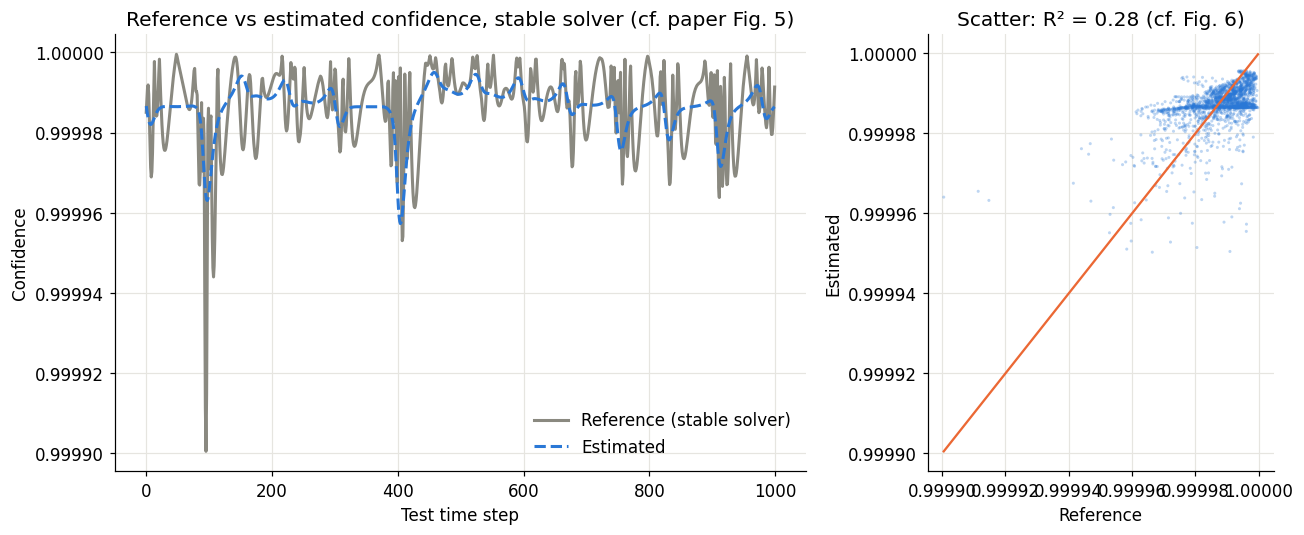

In [42]:
# Fig. 5/6 equivalent with the stable-readout confidence (same estimator, same selected features)
S_tr_ok, S_te_ok, C_tr_ok, C_te_ok = split(S, C_ok)
C_hat_ok = Ridge(alpha=1e-3).fit(S_tr_ok, C_tr_ok).predict(S_te_ok)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(C_te_ok[:1000], color=GREY, label="Reference (stable solver)")
axes[0].plot(C_hat_ok[:1000], "--", color=BLUE, label="Estimated")
axes[0].set_xlabel("Test time step"); axes[0].set_ylabel("Confidence")
axes[0].set_title("Reference vs estimated confidence, stable solver (cf. paper Fig. 5)")
axes[0].legend(loc="lower right")
axes[0].ticklabel_format(axis="y", useOffset=False)

axes[1].scatter(C_te_ok, C_hat_ok, s=4, alpha=0.3, color=BLUE, edgecolor="none")
lim = [min(C_te_ok.min(), C_hat_ok.min()), max(C_te_ok.max(), C_hat_ok.max())]
axes[1].plot(lim, lim, color=ORANGE, lw=1.5)
axes[1].set_xlabel("Reference"); axes[1].set_ylabel("Estimated")
axes[1].set_title(f"Scatter: R² = {r2_score(C_te_ok, C_hat_ok):.2f} (cf. Fig. 6)")
axes[1].ticklabel_format(useOffset=False)
plt.tight_layout(); plt.show()

### B3. "Same as last step" baseline, and autocorrelated statistics
Neighbouring time points are near-copies, so (1) a trivial predictor already scores highly, and (2) significance tests that assume independent samples become wildly overconfident. A non-parametric test (Wilcoxon) doesn't help, because the problem is dependence, not distribution shape.

In [22]:
ac_C = np.corrcoef(C[:-1], C[1:])[0, 1]
r2_persist = r2_score(C_te[1:], C_te[:-1])
print(f"Lag-1 autocorrelation of confidence: {ac_C:.4f}")
print(f"'Same as last step' baseline R²: {r2_persist:.4f}")

d_err = err_r - err_l
ac_d = np.corrcoef(d_err[:-1], d_err[1:])[0, 1]
n_eff = len(d_err)*(1 - ac_d)/(1 + ac_d)
t_eff = d_err.mean()/(d_err.std(ddof=1)/np.sqrt(n_eff))
print(f"\nPaired differences: autocorrelation {ac_d:.3f} → effective sample size ≈ {n_eff:.0f} (not {len(d_err)})")
print(f"t-statistic with effective n: {t_eff:.2f} (naive: {t_stat:.2f})")

# Moving-block bootstrap of the RMSE difference (blocks ≈ one Lyapunov time = 110 steps)
rng = np.random.default_rng(0); L = 110; m = len(C_te); boots = []
e_r, e_l = C_te - ridge_hat, C_te - lin_hat
for _ in range(2000):
    idx = np.concatenate([np.arange(st, st+L) for st in rng.integers(0, m-L, int(np.ceil(m/L)))])[:m]
    boots.append(np.sqrt(np.mean(e_r[idx]**2)) - np.sqrt(np.mean(e_l[idx]**2)))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"\nRMSE(ridge) − RMSE(linear) = {np.sqrt(np.mean(e_r**2)) - np.sqrt(np.mean(e_l**2)):.6f}, "
      f"95% block-bootstrap CI [{lo:.6f}, {hi:.6f}]")
SUMMARY["B. 'Same as last step' baseline R²"] = r2_persist
SUMMARY["B. Effective sample size (of 2,000 test points)"] = n_eff

Lag-1 autocorrelation of confidence: 0.9943
'Same as last step' baseline R²: 0.9886

Paired differences: autocorrelation 0.827 → effective sample size ≈ 189 (not 2000)
t-statistic with effective n: 0.95 (naive: 3.08)

RMSE(ridge) − RMSE(linear) = -0.000000, 95% block-bootstrap CI [-0.000000, 0.000000]


### B4. The three confidence definitions rank samples identically

In [23]:
print("Spearman rank correlation between definitions:")
print(f"  inverse vs exponential: {spearmanr(defs['inverse'], defs['exponential'])[0]:.6f}")
print(f"  inverse vs gaussian:    {spearmanr(defs['inverse'], defs['gaussian'])[0]:.6f}")

Spearman rank correlation between definitions:
  inverse vs exponential: 1.000000
  inverse vs gaussian:    1.000000


**Review note.** All three are monotone transforms of the same error, so agreement between them is guaranteed. That makes them one test, not three.

---
## Part C: Corrected experiment: does the reservoir predict *real* forecast error?

**Changes from Part A:**

1. **Longer simulation.** 600 time units, with the first 10 discarded as the start-up transient.
2. **Standardised features and a stable solver.** The readout predicts the *step change* (as in Gauthier et al., 2021).
3. **Three separate data segments, with gaps.** Readout training · estimator training · testing.
4. **Free-running forecasts.** From each start point the model feeds its own predictions back in, so errors grow as they would in a real forecast. The confidence target is the forecast error after *h* steps (log₁₀).
5. **Comparisons.** A linear readout (the paper's approach), and the raw x, y, z position alone, with linear and nonlinear (gradient-boosted trees) models.

In [24]:
T_long = 600
t_long = np.arange(0, T_long, dt)
U = solve_ivp(lorenz, (0, T_long), [1.0, 1.0, 1.0], t_eval=t_long,
              method="RK45", rtol=1e-9, atol=1e-9).y.T[1000:]       # drop 10 time units
iu = np.triu_indices(6)

def ngrc_feats(cur, prev):
    lin = np.concatenate([cur, prev], -1)
    q = (lin[..., :, None]*lin[..., None, :])[..., iu[0], iu[1]]
    return np.concatenate([np.ones(lin.shape[:-1] + (1,)), lin, q], -1)

F = ngrc_feats(U[1:-1], U[:-2])        # row i: state at i+1, previous at i
dU = U[2:] - U[1:-1]                    # target: step change to i+2
nF = len(F); seg1, seg2, gap = int(0.25*nF), int(0.5*nF), 500

mu, sd = F[:seg1, 1:].mean(0), F[:seg1, 1:].std(0)
zs = lambda X: np.concatenate([X[..., :1], (X[..., 1:] - mu)/sd], -1)
Z1 = zs(F[:seg1])
W_c = np.linalg.solve(Z1.T @ Z1 + 1e-6*np.eye(28), Z1.T @ dU[:seg1])
print(f"Samples after transient: {len(U)} | readout trained on first {seg1} | estimator trained on next segment | tested on last half")
onestep = np.abs(zs(F[seg2:]) @ W_c - dU[seg2:]).mean()
print(f"Teacher-forced one-step error on test segment: {onestep:.2e}")
SUMMARY["C. Teacher-forced one-step error"] = onestep

Samples after transient: 59000 | readout trained on first 14749 | estimator trained on next segment | tested on last half
Teacher-forced one-step error on test segment: 4.20e-05


### C1. Teacher-forced vs free-running: errors only grow when the model runs on its own

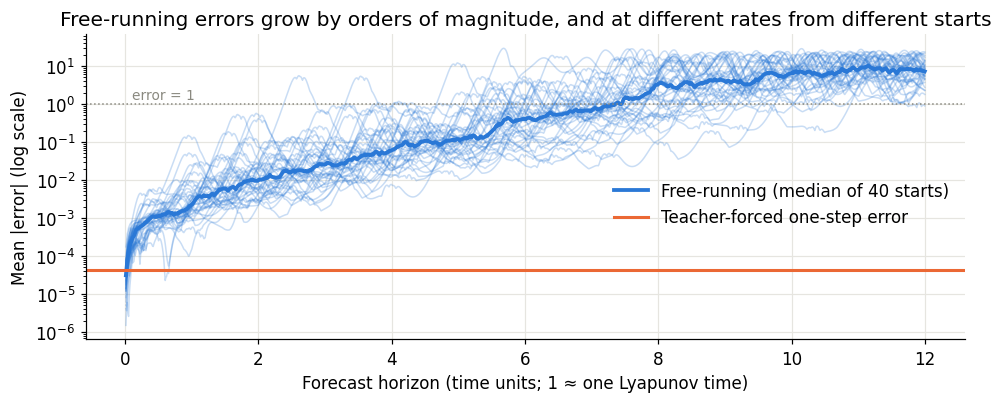

Steps until error > 1: median 577, range 238–962


In [25]:
def free_run(starts, horizons, tol=1.0, H_max=None):
    # Run the NGRC autonomously from many start indices at once (vectorised).
    H_max = H_max or max(horizons)
    cur, prev = U[starts + 1].copy(), U[starts].copy()
    errs = {h: None for h in horizons}; curve = []
    valid = np.full(len(starts), H_max); alive = np.ones(len(starts), bool)
    for h in range(1, H_max + 1):
        nxt = cur + zs(ngrc_feats(cur, prev)) @ W_c
        prev, cur = cur, nxt
        e = np.abs(cur - U[starts + 1 + h]).mean(1)
        curve.append(e)
        hit = alive & (~np.isfinite(e) | (e > tol)); valid[hit] = h; alive &= ~hit
        if h in errs: errs[h] = e
    return errs, valid, np.array(curve)

demo_starts = np.arange(seg2 + gap, seg2 + gap + 40*400, 400)
_, valid_demo, curves = free_run(demo_starts, [1], H_max=1200)

fig, ax = plt.subplots(figsize=(9, 3.8))
for c_ in curves.T: ax.semilogy(np.arange(1, 1201)*dt, c_, color=BLUE, alpha=0.25, lw=1)
ax.semilogy(np.arange(1, 1201)*dt, np.median(curves, 1), color=BLUE, lw=2.5, label="Free-running (median of 40 starts)")
ax.axhline(onestep, color=ORANGE, lw=2, label="Teacher-forced one-step error")
ax.axhline(1.0, color=GREY, lw=1, ls=":"); ax.text(0.1, 1.3, "error = 1", color=GREY, fontsize=9)
ax.set_xlabel("Forecast horizon (time units; 1 ≈ one Lyapunov time)"); ax.set_ylabel("Mean |error| (log scale)")
ax.set_title("Free-running errors grow by orders of magnitude, and at different rates from different starts")
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.32)); plt.tight_layout(); plt.show()
print(f"Steps until error > 1: median {np.median(valid_demo):.0f}, range {valid_demo.min()}–{valid_demo.max()}")

**Review note.** Teacher forcing hands the model the true position at every step, so mistakes are wiped out and the error stays tiny. Running freely, the error grows by about five orders of magnitude.

How long the forecast stays accurate depends on where it starts. That spread is genuine uncertainty, and it's what a confidence estimate should predict.

### C2. Can the starting state predict how large the forecast error will be?

In [26]:
horizons = [25, 50, 100, 200]
tr_starts = np.arange(seg1 + gap, seg2 - 400, 5)      # estimator-training segment
te_starts = np.arange(seg2 + gap, nF - 400, 5)        # test segment
E_tr, _, _ = free_run(tr_starts, horizons)
E_te, _, _ = free_run(te_starts, horizons)
print(f"Training starts: {len(tr_starts)}, test starts: {len(te_starts)}")

pos = lambda S: U[S + 1]
models = {
    "Linear on reservoir (paper's approach)": ("ridge", F),
    "Nonlinear on x, y, z only": ("gbm", None),
    "Nonlinear on reservoir": ("gbm", F),
}
def fit_predict(kind, Xtr, ytr, Xte):
    if kind == "ridge":
        sc = StandardScaler().fit(Xtr); return Ridge(alpha=1.0).fit(sc.transform(Xtr), ytr).predict(sc.transform(Xte))
    return HistGradientBoostingRegressor(max_iter=300, random_state=0).fit(Xtr, ytr).predict(Xte)

res = []; preds = {}
for h in horizons:
    ytr, yte = np.log10(E_tr[h]), np.log10(E_te[h])
    for name, (kind, feats) in models.items():
        Xtr = feats[tr_starts] if feats is not None else pos(tr_starts)
        Xte = feats[te_starts] if feats is not None else pos(te_starts)
        p = fit_predict(kind, Xtr, ytr, Xte); preds[(name, h)] = p
        res.append({"horizon (steps)": h, "horizon (time units)": h*dt, "model": name, "R2": r2_score(yte, p),
                    "Spearman": spearmanr(p, yte)[0]})
res = pd.DataFrame(res)
display(res.pivot(index="horizon (steps)", columns="model", values="R2").round(3))

Training starts: 2770, test starts: 5720


C:\Users\B00732999\PycharmProjects\pythonProject\venv\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\B00732999\PycharmProjects\pythonProject\venv\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\B00732999\AppData\Local\Programs\Python\Python39\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\B00732999\AppData\Local\Programs\Python\Python39\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\B00732999\AppData\Local\Programs\Python\Python39\l

model,Linear on reservoir (paper's approach),Nonlinear on reservoir,"Nonlinear on x, y, z only"
horizon (steps),,,
25,0.132,0.905,0.895
50,0.098,0.908,0.888
100,0.063,0.795,0.732
200,0.032,0.510,0.445


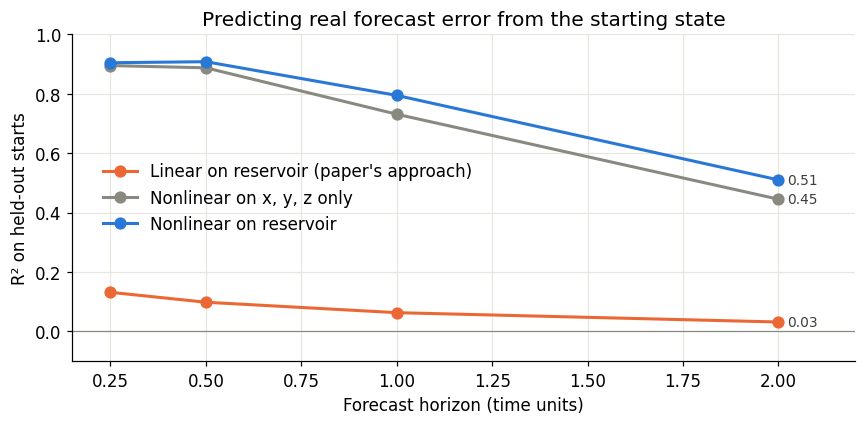

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = {"Linear on reservoir (paper's approach)": ORANGE, "Nonlinear on x, y, z only": GREY, "Nonlinear on reservoir": BLUE}
for name, col in colors.items():
    r = res[res.model == name]
    ax.plot(r["horizon (time units)"], r["R2"], "-o", color=col, ms=7, label=name)
    ax.annotate(f"{r['R2'].iloc[-1]:.2f}", (r["horizon (time units)"].iloc[-1], r["R2"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#3d3d3a")
ax.set_xlabel("Forecast horizon (time units)"); ax.set_ylabel("R² on held-out starts")
ax.set_ylim(-0.1, 1.0); ax.axhline(0, color=GREY, lw=0.8)
ax.set_title("Predicting real forecast error from the starting state")
ax.set_xlim(0.15, 2.2); ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.5)); plt.tight_layout(); plt.show()

### C3. Is the reservoir's advantage over raw position real? (block bootstrap)
Neighbouring start points overlap, so we resample contiguous blocks of 20 starts (100 steps ≈ one Lyapunov time) rather than individual points.

In [28]:
h = 100; yte = np.log10(E_te[h])
p_res, p_pos = preds[("Nonlinear on reservoir", h)], preds[("Nonlinear on x, y, z only", h)]
rng = np.random.default_rng(1); Lb = 20; m = len(yte); diffs = []
for _ in range(2000):
    idx = np.concatenate([np.arange(st, st+Lb) for st in rng.integers(0, m-Lb, int(np.ceil(m/Lb)))])[:m]
    diffs.append(r2_score(yte[idx], p_res[idx]) - r2_score(yte[idx], p_pos[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"At h = {h} steps: R² reservoir − R² position = {r2_score(yte, p_res) - r2_score(yte, p_pos):.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")
for name in models: SUMMARY[f"C. R² at 1 time unit: {name}"] = res[(res.model == name) & (res['horizon (steps)'] == 100)]["R2"].item()

At h = 100 steps: R² reservoir − R² position = 0.063, 95% CI [0.054, 0.072]


**Review note: what Part C shows.**

- **Real forecast error is predictable from the starting state.** Short-horizon error is very predictable, and that weakens with horizon. So the paper's core idea *can* hold for Lorenz.
- **But not with a linear readout.** That's the paper's method, and it explains almost none of the real error. A nonlinear model is needed.
- **Most of the information is in the position itself.** The reservoir adds a modest amount on top, mostly velocity information from the delayed copy.
- **This gives the student a valid version of Study I to report.** Confidence is predictable, but nonlinearly, and mostly from where the system is on the attractor.

### C4. Add the paper's own nonlinear method: quadratic ridge
For EEG (Study II), the paper's nonlinear estimator standardises the features, adds all pairwise products, and fits ridge with α = 100. Here the same recipe is applied to the Lorenz forecast-error targets, so the comparison covers both kinds of nonlinear model.

model,Linear on reservoir (paper's approach),Quadratic ridge on reservoir (paper's EEG method),"Nonlinear on x, y, z only",Nonlinear on reservoir
horizon (steps),,,,
25,0.132,0.187,0.895,0.905
50,0.098,0.151,0.888,0.908
100,0.063,0.071,0.732,0.795
200,0.032,0.043,0.445,0.510


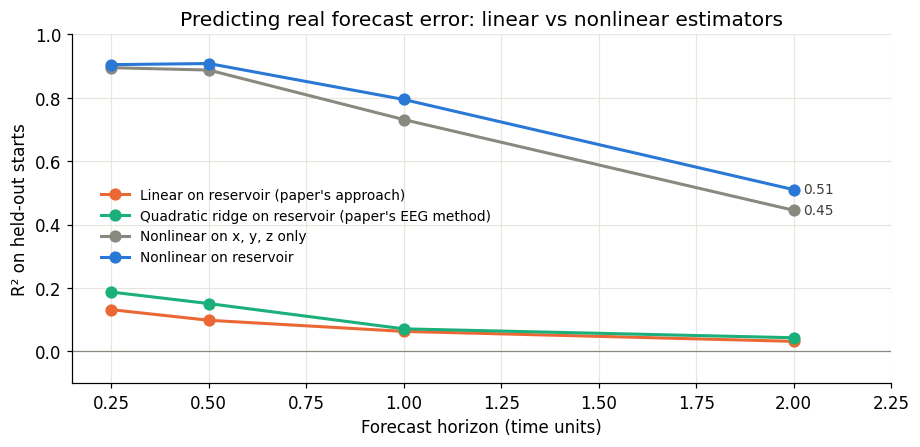

In [29]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

def quad_ridge(Xtr, ytr, Xte, alpha=100.0):
    # Same recipe as the paper's EEG estimator: standardise -> pairwise products -> standardise -> ridge(α=100)
    m = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=alpha))
    return m.fit(Xtr, ytr).predict(Xte)

QUAD = "Quadratic ridge on reservoir (paper's EEG method)"
for h in horizons:
    ytr, yte = np.log10(E_tr[h]), np.log10(E_te[h])
    p = quad_ridge(F[tr_starts][:, 1:], ytr, F[te_starts][:, 1:])   # drop the constant column
    preds[(QUAD, h)] = p
    res = pd.concat([res, pd.DataFrame([{"horizon (steps)": h, "horizon (time units)": h*dt, "model": QUAD,
                                         "R2": r2_score(yte, p), "Spearman": spearmanr(p, yte)[0]}])], ignore_index=True)

order = ["Linear on reservoir (paper's approach)", QUAD, "Nonlinear on x, y, z only", "Nonlinear on reservoir"]
display(res.pivot(index="horizon (steps)", columns="model", values="R2")[order].round(3))

colors[QUAD] = AQUA
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for name in order:
    r = res[res.model == name]
    ax.plot(r["horizon (time units)"], r["R2"], "-o", color=colors[name], ms=7, label=name)
    if r["R2"].iloc[-1] > 0.1:   # label the end of the separated lines only (the two linear ones overlap near 0)
        ax.annotate(f"{r['R2'].iloc[-1]:.2f}", (r["horizon (time units)"].iloc[-1], r["R2"].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#3d3d3a")
ax.set_xlim(0.15, 2.25); ax.set_ylim(-0.1, 1.0); ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlabel("Forecast horizon (time units)"); ax.set_ylabel("R² on held-out starts")
ax.set_title("Predicting real forecast error: linear vs nonlinear estimators")
ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.45), fontsize=9); plt.tight_layout(); plt.show()

### C5. The equivalent of the paper's Figs. 5 and 6, on a real target
Paper Figs. 5–6 show estimated vs reference confidence with near-perfect overlap. Here are the same two views, with the forecast error 1 time unit (100 steps) ahead as the target, for the linear and nonlinear estimators.

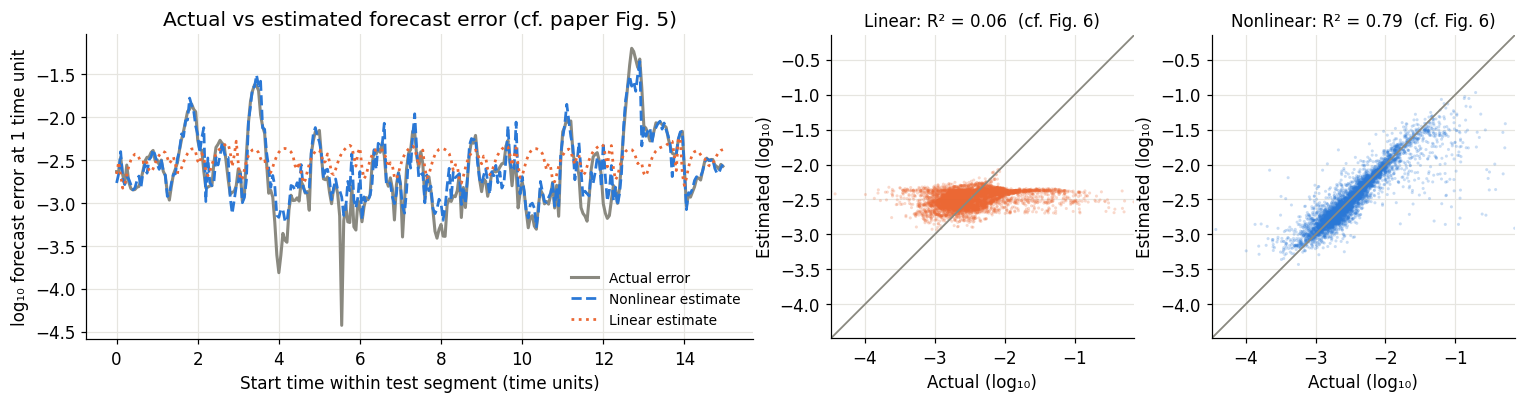

In [64]:
h = 100
y_true = np.log10(E_te[h])
lin_name, nl_name = "Linear on reservoir (paper's approach)", "Nonlinear on reservoir"
p_lin, p_nl = preds[(lin_name, h)], preds[(nl_name, h)]
seg = slice(0, 300)   # first 300 test starts (start points are 5 steps apart → 15 time units)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1, 1]})
t_axis = (te_starts[seg] - te_starts[0])*dt
axes[0].plot(t_axis, y_true[seg], color=GREY, lw=2, label="Actual error")
axes[0].plot(t_axis, p_nl[seg], "--", color=BLUE, lw=1.8, label="Nonlinear estimate")
axes[0].plot(t_axis, p_lin[seg], ":", color=ORANGE, lw=1.8, label="Linear estimate")
axes[0].set_xlabel("Start time within test segment (time units)"); axes[0].set_ylabel("log₁₀ forecast error at 1 time unit")
axes[0].set_title("Actual vs estimated forecast error (cf. paper Fig. 5)"); axes[0].legend(fontsize=9, loc="lower right")

lims = [y_true.min(), y_true.max()]
for ax, p, name, col in [(axes[1], p_lin, "Linear", ORANGE), (axes[2], p_nl, "Nonlinear", BLUE)]:
    ax.scatter(y_true, p, s=4, alpha=0.25, color=col, edgecolor="none")
    ax.plot(lims, lims, color=GREY, lw=1.2)
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
    ax.set_xlabel("Actual (log₁₀)"); ax.set_ylabel("Estimated (log₁₀)")
    ax.set_title(f"{name}: R² = {r2_score(y_true, p):.2f}  (cf. Fig. 6)", fontsize=11)
plt.tight_layout(); 
# plt.savefig("fig_5_6.png")
# plt.show()

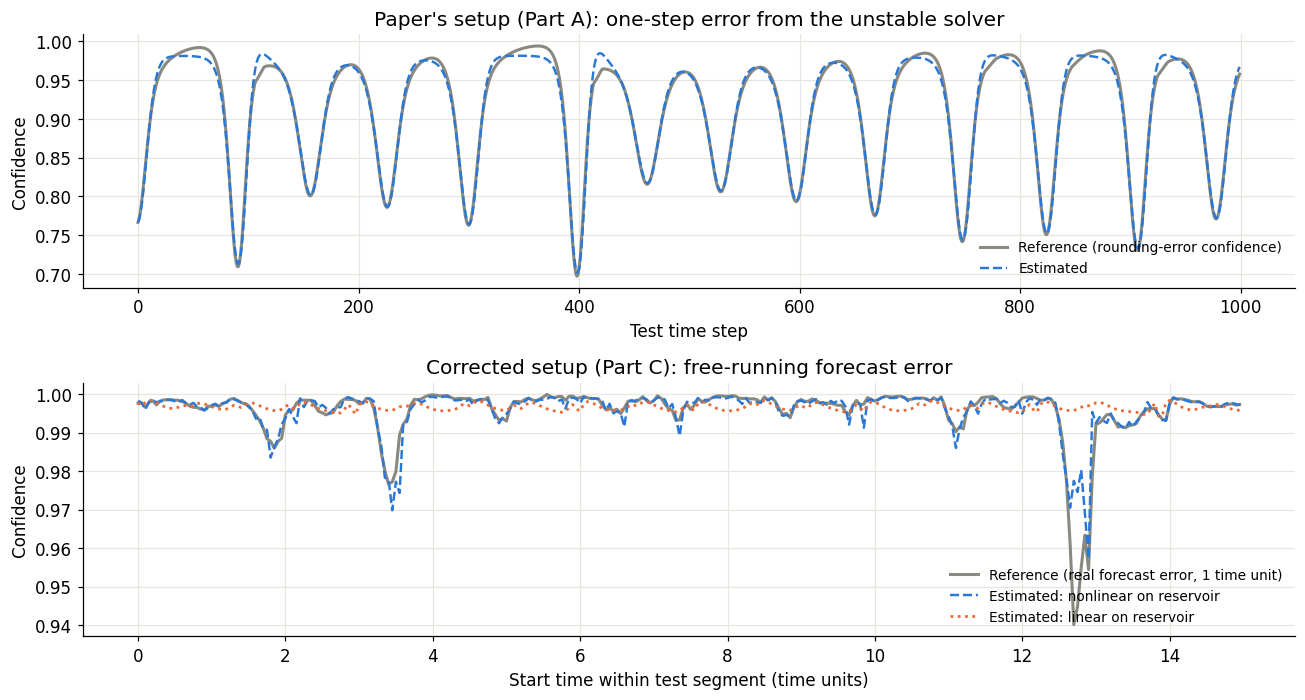

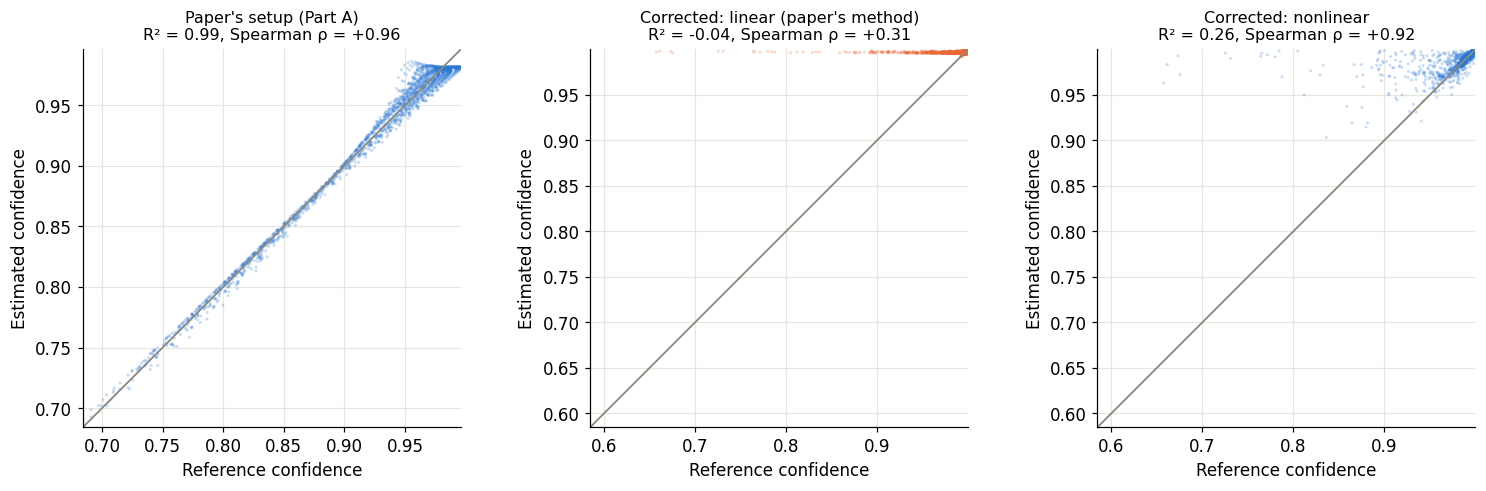

In [67]:
# Reference vs estimated confidence, in the paper's units C = 1/(1+e), for direct comparison with Figs. 5–6
C_ref_real = 1/(1 + 10**y_true)      # reference: real forecast error at 1 time unit, paper's formula
C_est_lin  = 1/(1 + 10**p_lin)       # estimated from linear readout on reservoir (paper's approach)
C_est_nl   = 1/(1 + 10**p_nl)        # estimated from nonlinear model on reservoir

# --- Fig. 5 equivalent: confidence over time ---
seg = slice(0, 300)
t_axis = (te_starts[seg] - te_starts[0])*dt
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
axes[0].plot(C_te[:1000], color=GREY, lw=2, label="Reference (rounding-error confidence)")
axes[0].plot(C_hat[:1000], "--", color=BLUE, lw=1.6, label="Estimated")
axes[0].set_title("Paper's setup (Part A): one-step error from the unstable solver")
axes[0].set_xlabel("Test time step"); axes[0].set_ylabel("Confidence"); axes[0].legend(loc="lower right", fontsize=9)

axes[1].plot(t_axis, C_ref_real[seg], color=GREY, lw=2, label="Reference (real forecast error, 1 time unit)")
axes[1].plot(t_axis, C_est_nl[seg], "--", color=BLUE, lw=1.6, label="Estimated: nonlinear on reservoir")
axes[1].plot(t_axis, C_est_lin[seg], ":", color=ORANGE, lw=1.8, label="Estimated: linear on reservoir")
axes[1].set_title("Corrected setup (Part C): free-running forecast error")
axes[1].set_xlabel("Start time within test segment (time units)"); axes[1].set_ylabel("Confidence")
axes[1].ticklabel_format(axis="y", useOffset=False); axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout(); 
plt.savefig("fig_5.png",dpi=300)

# plt.show()

# --- Fig. 6 equivalent: estimated vs reference confidence ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
panels = [(axes[0], C_te, C_hat, BLUE, "Paper's setup (Part A)"),
          (axes[1], C_ref_real, C_est_lin, ORANGE, "Corrected: linear (paper's method)"),
          (axes[2], C_ref_real, C_est_nl, BLUE, "Corrected: nonlinear")]
for ax, ref, est, col, title in panels:
    ax.scatter(ref, est, s=4, alpha=0.25, color=col, edgecolor="none")
    lim = [min(ref.min(), est.min()), max(ref.max(), est.max())]
    ax.plot(lim, lim, color=GREY, lw=1.2)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("Reference confidence"); ax.set_ylabel("Estimated confidence")
    ax.set_title(f"{title}\nR² = {r2_score(ref, est):.2f}, Spearman ρ = {spearmanr(ref, est)[0]:+.2f}", fontsize=10.5)
    ax.ticklabel_format(useOffset=False)
plt.tight_layout();
plt.savefig("fig_6.png",dpi=300)
#  plt.show()

### C6. Is the estimate useful? Forecasts grouped by estimated reliability
This is the Lorenz version of the paper's selective-decoding idea (EEG Figs. 15–16). Test forecasts are sorted into ten equal groups by *estimated* error, and the plot shows the *actual* median error in each group. A useful estimator gives a rising staircase: forecasts it trusts most really are the most accurate.

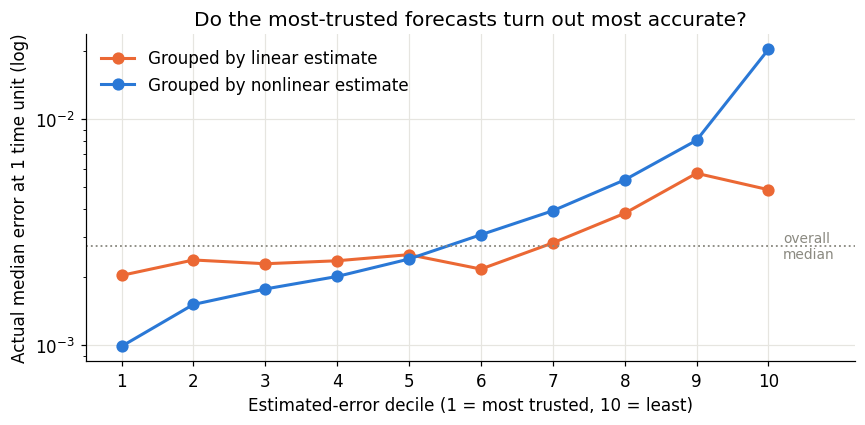

Nonlinear estimator: most-trusted 10% have median error 9.9e-04, least-trusted 10% 2.0e-02 (×21 difference)


In [31]:
def decile_medians(pred, actual):
    q = pd.qcut(pred, 10, labels=False, duplicates="drop")
    return pd.Series(actual).groupby(q).median().values

actual_err = E_te[h]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, 11)
ax.plot(x, decile_medians(p_lin, actual_err), "-o", color=ORANGE, ms=7, label="Grouped by linear estimate")
ax.plot(x, decile_medians(p_nl, actual_err), "-o", color=BLUE, ms=7, label="Grouped by nonlinear estimate")
ax.axhline(np.median(actual_err), color=GREY, ls=":", lw=1.2)
ax.text(10.2, np.median(actual_err), "overall\nmedian", va="center", fontsize=9, color=GREY)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xlim(0.5, 11.2)
ax.set_xlabel("Estimated-error decile (1 = most trusted, 10 = least)")
ax.set_ylabel("Actual median error at 1 time unit (log)")
ax.set_title("Do the most-trusted forecasts turn out most accurate?")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

top, bottom = decile_medians(p_nl, actual_err)[[0, -1]]
print(f"Nonlinear estimator: most-trusted 10% have median error {top:.1e}, least-trusted 10% {bottom:.1e} "
      f"(×{bottom/top:.0f} difference)")

### C7. Where on the attractor are forecasts unreliable?
Each dot is a test start point, placed by its x and z position and coloured by forecast error (darker = larger). Left: actual error. Right: the nonlinear estimate. This shows *why* a linear model fails: reliability depends on position in a curved, patchy way, which a weighted sum of features can't follow.

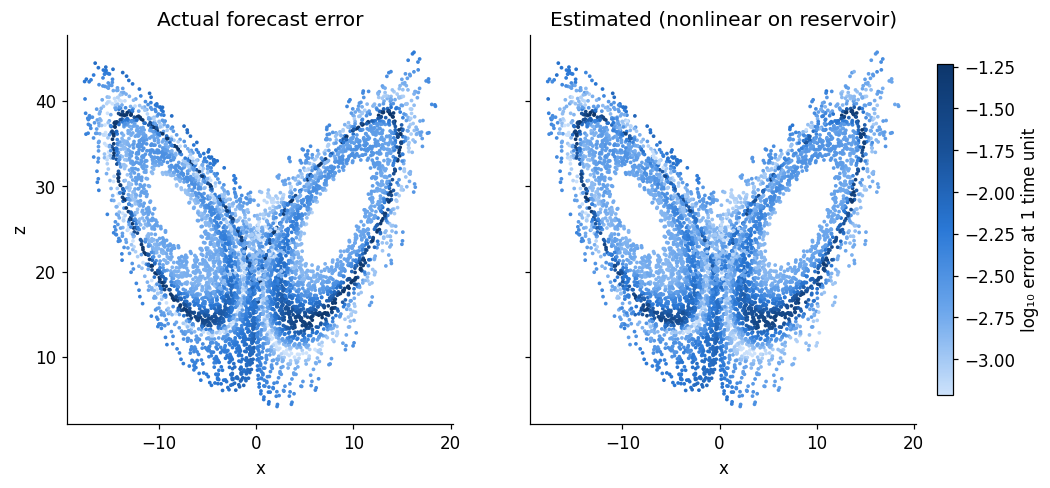

In [32]:
from matplotlib.colors import LinearSegmentedColormap
seq = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
P = pos(te_starts)
vmin, vmax = np.percentile(y_true, [2, 98])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, vals, title in [(axes[0], y_true, "Actual forecast error"), (axes[1], p_nl, "Estimated (nonlinear on reservoir)")]:
    sc = ax.scatter(P[:, 0], P[:, 2], c=vals, cmap=seq, vmin=vmin, vmax=vmax, s=6, edgecolor="none")
    ax.set_title(title); ax.set_xlabel("x"); ax.grid(False)
axes[0].set_ylabel("z")
cb = fig.colorbar(sc, ax=axes, shrink=0.85, pad=0.02); cb.set_label("log₁₀ error at 1 time unit")
plt.show()

### C8. Which features matter? Paper's ranking vs real forecast error
Paper Fig. 4 ranks features by correlation with its (artefactual) confidence. Here the same features are ranked by rank correlation (Spearman) with the *real* forecast error. Paper-selected features are marked ●.

Note the two rankings come from different simulations (100 vs 600 time units), but the feature definitions are identical.

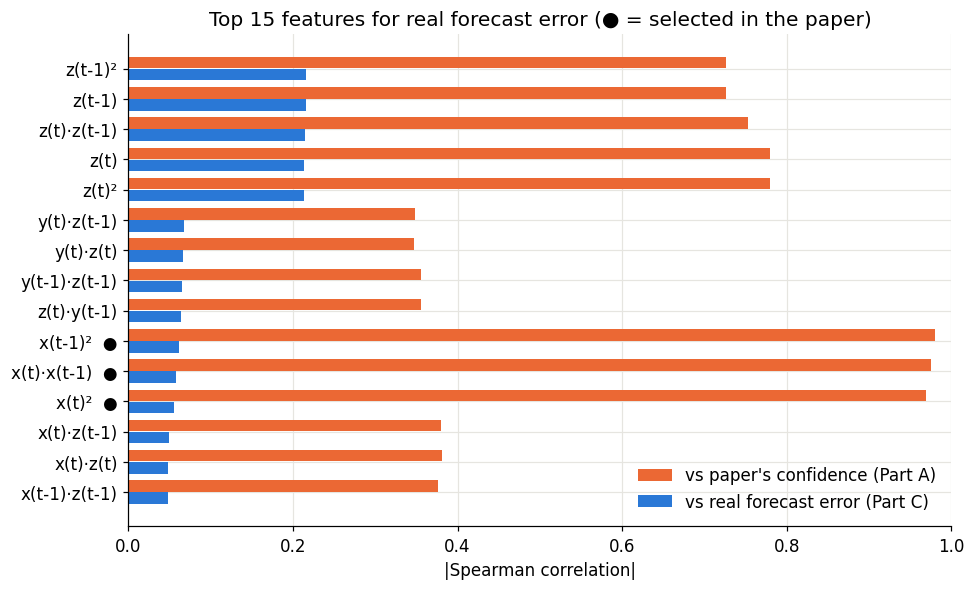

Features the paper selected: ['x(t-1)²', 'x(t)·x(t-1)', 'x(t)²', 'x(t-1)·y(t-1)']
Top 8 for real forecast error: ['z(t-1)²', 'z(t-1)', 'z(t)·z(t-1)', 'z(t)', 'z(t)²', 'y(t)·z(t-1)', 'y(t)·z(t)', 'y(t-1)·z(t-1)']


In [33]:
names27 = feature_names[1:]
rho_paper = np.array([abs(spearmanr(reservoir[:, i], C)[0]) for i in range(1, 28)])
rho_real = np.array([abs(spearmanr(F[te_starts][:, i], y_true)[0]) for i in range(1, 28)])
# rho_paper = np.array([abs(pearsonr(reservoir[:, i], C)[0]) for i in range(1, 28)])
# rho_real = np.array([abs(pearsonr(F[te_starts][:, i], y_true)[0]) for i in range(1, 28)])
order_idx = np.argsort(-rho_real)[:15]
sel_set = set(selected_idx)

fig, ax = plt.subplots(figsize=(9, 5.5))
yy = np.arange(len(order_idx))
ax.barh(yy - 0.2, rho_paper[order_idx], height=0.38, color=ORANGE, label="vs paper's confidence (Part A)")
ax.barh(yy + 0.2, rho_real[order_idx], height=0.38, color=BLUE, label="vs real forecast error (Part C)")
ax.set_yticks(yy, [f"{names27[i]}{'  ●' if (i + 1) in sel_set else ''}" for i in order_idx])
ax.invert_yaxis(); ax.set_xlabel("|Spearman correlation|"); ax.set_xlim(0, 1)
ax.set_title("Top 15 features for real forecast error (● = selected in the paper)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
print("Features the paper selected:", [feature_names[i] for i in selected_idx])
print("Top 8 for real forecast error:", [names27[i] for i in np.argsort(-rho_real)[:8]])

### C9. Does the paper's own confidence measure track real forecast reliability?
Here the repo's exact method (raw features, `np.linalg.inv`, teacher-forced one-step error, C = 1/(1+e)) is applied to the Part C trajectory. Its confidence at each test start is then compared with how accurate the real 1-time-unit forecast from that start turns out to be. If the paper's confidence were meaningful, high confidence should go with low real error.

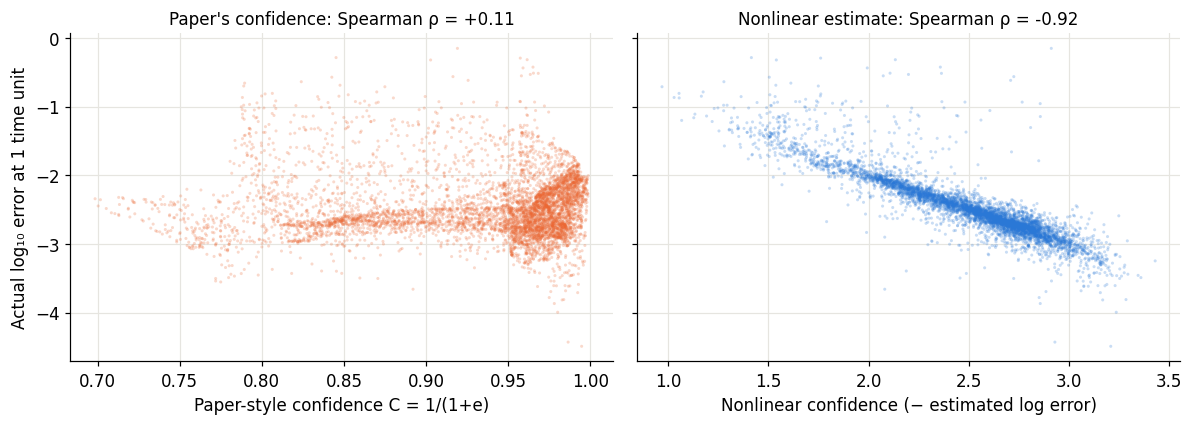

Good confidence should give a strongly NEGATIVE ρ: higher confidence, lower actual error.


In [34]:
# Repo method on Part C data: raw features, inv, trained on the readout segment, next-state target
Fr, Yr = F[:seg1], U[2:2 + seg1]
Wr = (Yr.T @ Fr) @ np.linalg.inv(Fr.T @ Fr + 2.5e-6*np.eye(28))
C_paper_style = 1/(1 + np.abs(U[2 + te_starts] - F[te_starts] @ Wr.T).mean(1))

rho_ps = spearmanr(C_paper_style, y_true)[0]
rho_nl = spearmanr(-p_nl, y_true)[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].scatter(C_paper_style, y_true, s=4, alpha=0.25, color=ORANGE, edgecolor="none")
axes[0].set_xlabel("Paper-style confidence C = 1/(1+e)"); axes[0].set_ylabel("Actual log₁₀ error at 1 time unit")
axes[0].set_title(f"Paper's confidence: Spearman ρ = {rho_ps:+.2f}", fontsize=11)
axes[1].scatter(-p_nl, y_true, s=4, alpha=0.25, color=BLUE, edgecolor="none")
axes[1].set_xlabel("Nonlinear confidence (− estimated log error)")
axes[1].set_title(f"Nonlinear estimate: Spearman ρ = {rho_nl:+.2f}", fontsize=11)
plt.tight_layout(); plt.show()
print("Good confidence should give a strongly NEGATIVE ρ: higher confidence, lower actual error.")
SUMMARY["C. Spearman ρ, paper-style confidence vs real error"] = rho_ps
SUMMARY["C. Spearman ρ, nonlinear confidence vs real error"] = rho_nl

---
## Part D: Summary of key numbers from this run

---
## Part E: Robust version of the Part C experiment

Part C was a quick, single-run check. Part E repeats it properly:

1. **Several independent trajectories.** Six Lorenz trajectories, each from a different random starting point. One is used only to train the NGRC forecaster. The other five are used in a *leave-one-trajectory-out* loop: train the estimators on four, test on the fifth, rotate.
2. **Everything tuned on training data only.**
   - The forecaster's ridge α is chosen by forecast stability on part of its own trajectory.
   - Every estimator's settings are chosen by cross-validation *inside* the four training trajectories (grouped by trajectory, so no trajectory is in both halves of a split).
3. **Standard predictability baselines.**
   - *Local stretching rate*: how fast nearby points are pulling apart **right now**, computed from the Lorenz equations at the start point. It uses current information only, like the reservoir.
   - *Finite-time Lyapunov exponent (FTLE)*: how much a small perturbation actually grows **over the forecast horizon** along the true path. This uses future information, so it's a ceiling for how predictable forecast error is from the dynamics, not a fair competitor.
4. **The paper's confidence measure** (repo method) is evaluated on the same held-out forecasts.

Results are reported as **mean ± spread across the five held-out trajectories**, so they show how stable each number is, not just one value.

*Runtime: roughly 3–6 minutes on a laptop; the cross-validated tuning is the slow part.*

In [43]:
# ---------- Part E setup: trajectories, forecaster tuned on its own data ----------
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

E_SIGMA, E_RHO, E_BETA = 10.0, 28.0, 8/3
E_DT, E_T, E_TRANSIENT = 0.01, 320, 20          # 320 time units per trajectory, first 20 discarded
E_NTRAJ = 6                                      # trajectory 0 = forecaster training; 1..5 = estimator data
E_HORIZONS = [25, 50, 100, 200]
E_STRIDE, E_MARGIN = 20, 400                     # start points every 20 steps; leave room for the longest forecast

rng_E = np.random.default_rng(2026)
E_trajs = []
for k in range(E_NTRAJ):
    u0 = [rng_E.uniform(-15, 15), rng_E.uniform(-15, 15), rng_E.uniform(5, 40)]
    t_ = np.arange(0, E_T, E_DT)
    traj = solve_ivp(lorenz, (0, E_T), u0, t_eval=t_, method="RK45", rtol=1e-9, atol=1e-9).y.T
    E_trajs.append(traj[int(E_TRANSIENT/E_DT):])
print(f"{E_NTRAJ} trajectories × {len(E_trajs[0])} samples (after discarding {E_TRANSIENT} time units)")

E_iu = np.triu_indices(6)
def E_feats(cur, prev):
    lin = np.concatenate([cur, prev], -1)
    q = (lin[..., :, None]*lin[..., None, :])[..., E_iu[0], E_iu[1]]
    return np.concatenate([np.ones(lin.shape[:-1] + (1,)), lin, q], -1)

# Forecaster data: trajectory 0 only
U0 = E_trajs[0]
F0, dU0 = E_feats(U0[1:-1], U0[:-2]), U0[2:] - U0[1:-1]
n_fit = int(0.7*len(F0))                         # 70% to fit, 30% to judge forecast stability
E_mu, E_sd = F0[:n_fit, 1:].mean(0), F0[:n_fit, 1:].std(0)
E_z = lambda X: np.concatenate([X[..., :1], (X[..., 1:] - E_mu)/E_sd], -1)

def E_fit_readout(alpha, rows):
    Z = E_z(F0[rows]); return np.linalg.solve(Z.T @ Z + alpha*np.eye(28), Z.T @ dU0[rows])

def E_free_run(U, starts, W, H, horizons=(), tol=1.0):
    # Vectorised autonomous forecasts from many start indices on trajectory U
    cur, prev = U[starts + 1].copy(), U[starts].copy()
    errs, valid, alive = {}, np.full(len(starts), H), np.ones(len(starts), bool)
    with np.errstate(over="ignore", invalid="ignore"):
        for h in range(1, H + 1):
            nxt = cur + E_z(E_feats(cur, prev)) @ W
            prev, cur = cur, nxt
            e = np.abs(cur - U[starts + 1 + h]).mean(1)
            hit = alive & (~np.isfinite(e) | (e > tol)); valid[hit] = h; alive &= ~hit
            if h in horizons: errs[h] = e
    return errs, valid

# Tune α on trajectory 0's held-back 30%: pick the α whose free-running forecasts stay accurate longest
val_starts = np.arange(n_fit + 200, len(F0) - 1300, 50)
alpha_grid = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
alpha_scores = []
for a in alpha_grid:
    _, vt = E_free_run(U0, val_starts, E_fit_readout(a, slice(0, n_fit)), 1200)
    alpha_scores.append(np.median(vt))
E_alpha = alpha_grid[int(np.argmax(alpha_scores))]
W_E = E_fit_readout(E_alpha, slice(0, len(F0)))   # refit on all of trajectory 0
print("Validation median steps before error > 1, by α:", dict(zip(alpha_grid, alpha_scores)))
print(f"Chosen α = {E_alpha:g} (on trajectory 0's own validation segment only)")

6 trajectories × 30000 samples (after discarding 20 time units)
Validation median steps before error > 1, by α: {1e-08: 15.0, 1e-07: 22.0, 1e-06: 603.0, 1e-05: 495.0, 0.0001: 467.5, 0.001: 566.0, 0.01: 366.5}
Chosen α = 1e-06 (on trajectory 0's own validation segment only)


In [44]:
# ---------- Targets, features and dynamical baselines for trajectories 1..5 ----------
def E_jac(s):
    # Lorenz Jacobian at states s (n×3) -> (n×3×3)
    x, y, z = s[:, 0], s[:, 1], s[:, 2]
    J = np.zeros((len(s), 3, 3))
    J[:, 0, 0], J[:, 0, 1] = -E_SIGMA, E_SIGMA
    J[:, 1, 0], J[:, 1, 1], J[:, 1, 2] = E_RHO - z, -1.0, -x
    J[:, 2, 0], J[:, 2, 1], J[:, 2, 2] = y, x, -E_BETA
    return J

def E_ftle_logs(U, starts, horizons):
    # log of the largest stretching factor of a tiny perturbation along the TRUE path (uses future: a ceiling)
    M = np.repeat(np.eye(3)[None], len(starts), 0); out = {}
    for h in range(1, max(horizons) + 1):
        M = (np.eye(3)[None] + E_DT*E_jac(U[starts + h])) @ M
        if h in horizons: out[h] = np.log(np.linalg.svd(M, compute_uv=False)[:, 0])
    return out

def E_local_stretch(U, starts):
    # Instantaneous stretching rate at the start point (current information only)
    J = E_jac(U[starts + 1]); return np.linalg.eigvalsh(0.5*(J + J.transpose(0, 2, 1)))[:, -1]

# Paper-style confidence (repo method): raw features, np.linalg.inv, one-step next-state error, C = 1/(1+e)
Fr0 = F0[:n_fit]; Yr0 = U0[2:2 + n_fit]
W_paper = (Yr0.T @ Fr0) @ np.linalg.inv(Fr0.T @ Fr0 + 2.5e-6*np.eye(28))

E_data = []
for k in range(1, E_NTRAJ):
    U = E_trajs[k]; Fk = E_feats(U[1:-1], U[:-2])
    starts = np.arange(10, len(Fk) - E_MARGIN, E_STRIDE)
    errs, valid = E_free_run(U, starts, W_E, max(E_HORIZONS), E_HORIZONS)
    E_data.append({
        "traj": k, "starts": starts, "U": U,
        "X_res": Fk[starts][:, 1:],                     # 27 reservoir features (constant dropped)
        "X_pos": U[starts + 1],                         # x, y, z only
        "y": {h: np.log10(errs[h]) for h in E_HORIZONS},
        "valid": valid,
        "stretch": E_local_stretch(U, starts),
        "ftle": E_ftle_logs(U, starts, E_HORIZONS),
        "C_paper": 1/(1 + np.abs(U[starts + 2] - Fk[starts] @ W_paper.T).mean(1)),
    })
print("Starts per held-out trajectory:", [len(d["starts"]) for d in E_data])
print("Median steps before forecast error > 1, per trajectory:", [int(np.median(d["valid"])) for d in E_data])

Starts per held-out trajectory: [1480, 1480, 1480, 1480, 1480]
Median steps before forecast error > 1, per trajectory: [200, 200, 200, 200, 200]


In [45]:
# ---------- Leave-one-trajectory-out evaluation, all tuning inside the training trajectories ----------
GBM_GRID = [dict(learning_rate=0.1, max_leaf_nodes=15, max_iter=200),
            dict(learning_rate=0.1, max_leaf_nodes=31, max_iter=300)]
ALPHAS = np.logspace(-3, 4, 8)

def E_cv_score(make_model, X, y, groups):
    sc = []
    for tr_i, va_i in GroupKFold(n_splits=len(np.unique(groups))).split(X, y, groups):
        sc.append(r2_score(y[va_i], make_model().fit(X[tr_i], y[tr_i]).predict(X[va_i])))
    return np.mean(sc)

def E_fit_predict(kind, Xtr, ytr, gtr, Xte):
    if kind == "linear":
        best = max(ALPHAS, key=lambda a: E_cv_score(lambda: make_pipeline(StandardScaler(), Ridge(alpha=a)), Xtr, ytr, gtr))
        return make_pipeline(StandardScaler(), Ridge(alpha=best)).fit(Xtr, ytr).predict(Xte), best
    if kind == "quad":
        best = max(ALPHAS[::2], key=lambda a: E_cv_score(lambda: make_pipeline(
            StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=a)), Xtr, ytr, gtr))
        m = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=best))
        return m.fit(Xtr, ytr).predict(Xte), best
    if kind == "gbm":
        best = max(GBM_GRID, key=lambda p: E_cv_score(lambda: HistGradientBoostingRegressor(random_state=0, **p), Xtr, ytr, gtr))
        return HistGradientBoostingRegressor(random_state=0, **best).fit(Xtr, ytr).predict(Xte), best
    if kind == "one":   # single-number baselines: straight-line fit on training trajectories
        return LinearRegression().fit(Xtr, ytr).predict(Xte), None

E_MODELS = {   # name: (kind, how to get X for a trajectory record d and horizon h)
    "Linear on reservoir (paper's approach)":   ("linear", lambda d, h: d["X_res"]),
    "Quadratic ridge on reservoir (paper's EEG method)": ("quad", lambda d, h: d["X_res"]),
    "Local stretching rate (current state)":    ("one",    lambda d, h: d["stretch"][:, None]),
    "Nonlinear on x, y, z only":                 ("gbm",    lambda d, h: d["X_pos"]),
    "Nonlinear on reservoir":                    ("gbm",    lambda d, h: d["X_res"]),
    "FTLE over horizon (uses future: ceiling)":  ("one",    lambda d, h: d["ftle"][h][:, None]),
}

E_rows, E_preds = [], {}
for i_te, d_te in enumerate(E_data):
    train = [d for j, d in enumerate(E_data) if j != i_te]
    gtr = np.concatenate([np.full(len(d["starts"]), d["traj"]) for d in train])
    for h in E_HORIZONS:
        ytr = np.concatenate([d["y"][h] for d in train]); yte = d_te["y"][h]
        for name, (kind, getX) in E_MODELS.items():
            Xtr = np.vstack([getX(d, h) for d in train]); Xte = getX(d_te, h)
            p, chosen = E_fit_predict(kind, Xtr, ytr, gtr, Xte)
            E_preds[(name, h, d_te["traj"])] = p
            E_rows.append({"held-out trajectory": d_te["traj"], "horizon": h, "model": name,
                           "R2": r2_score(yte, p), "Spearman": spearmanr(p, yte)[0], "chosen": str(chosen)})
        # paper-style confidence: no fitting; high confidence should mean LOW error, so use −C as the error score
        E_rows.append({"held-out trajectory": d_te["traj"], "horizon": h, "model": "Paper's confidence (repo method)",
                       "R2": np.nan, "Spearman": spearmanr(-d_te["C_paper"], yte)[0], "chosen": ""})
    print(f"held-out trajectory {d_te['traj']} done")
E_res = pd.DataFrame(E_rows)

def mean_sd(s): return f"{s.mean():.2f} ± {s.std(ddof=1):.2f}"
print("\nR² on held-out trajectories (mean ± SD across the 5):")
display(E_res.dropna(subset=["R2"]).pivot_table(index="model", columns="horizon", values="R2", aggfunc=mean_sd)
        .reindex(list(E_MODELS)))
print("Spearman ρ between estimate and actual error (mean ± SD); paper's confidence uses −C so positive = right direction:")
display(E_res.pivot_table(index="model", columns="horizon", values="Spearman", aggfunc=mean_sd)
        .reindex(["Paper's confidence (repo method)"] + list(E_MODELS)))

held-out trajectory 1 done
held-out trajectory 2 done
held-out trajectory 3 done
held-out trajectory 4 done
held-out trajectory 5 done

R² on held-out trajectories (mean ± SD across the 5):


horizon,25,50,100,200
model,,,,
Linear on reservoir (paper's approach),0.29 ± 0.01,0.18 ± 0.01,0.05 ± 0.02,0.07 ± 0.02
Quadratic ridge on reservoir (paper's EEG method),0.55 ± 0.02,0.39 ± 0.03,0.13 ± 0.02,0.23 ± 0.04
Local stretching rate (current state),0.01 ± 0.00,0.06 ± 0.01,0.03 ± 0.00,0.01 ± 0.00
"Nonlinear on x, y, z only",0.93 ± 0.01,0.93 ± 0.00,0.81 ± 0.02,0.62 ± 0.04
Nonlinear on reservoir,0.96 ± 0.01,0.96 ± 0.00,0.88 ± 0.02,0.70 ± 0.04
FTLE over horizon (uses future: ceiling),0.04 ± 0.01,0.32 ± 0.01,0.57 ± 0.01,0.23 ± 0.05


Spearman ρ between estimate and actual error (mean ± SD); paper's confidence uses −C so positive = right direction:


horizon,25,50,100,200
model,,,,
Paper's confidence (repo method),0.02 ± 0.02,0.26 ± 0.02,-0.23 ± 0.01,0.14 ± 0.01
Linear on reservoir (paper's approach),0.57 ± 0.02,0.44 ± 0.01,0.27 ± 0.03,0.23 ± 0.02
Quadratic ridge on reservoir (paper's EEG method),0.76 ± 0.02,0.64 ± 0.01,0.37 ± 0.02,0.51 ± 0.03
Local stretching rate (current state),0.14 ± 0.02,0.28 ± 0.03,0.25 ± 0.01,0.12 ± 0.02
"Nonlinear on x, y, z only",0.97 ± 0.00,0.97 ± 0.00,0.93 ± 0.01,0.83 ± 0.01
Nonlinear on reservoir,0.98 ± 0.00,0.98 ± 0.00,0.96 ± 0.00,0.88 ± 0.01
FTLE over horizon (uses future: ceiling),0.23 ± 0.02,0.46 ± 0.02,0.55 ± 0.01,0.35 ± 0.02


### E1. Accuracy vs forecast horizon, with spread across held-out trajectories
Same layout as C4. Dots are means over the five held-out trajectories; bars show the lowest and highest trajectory.

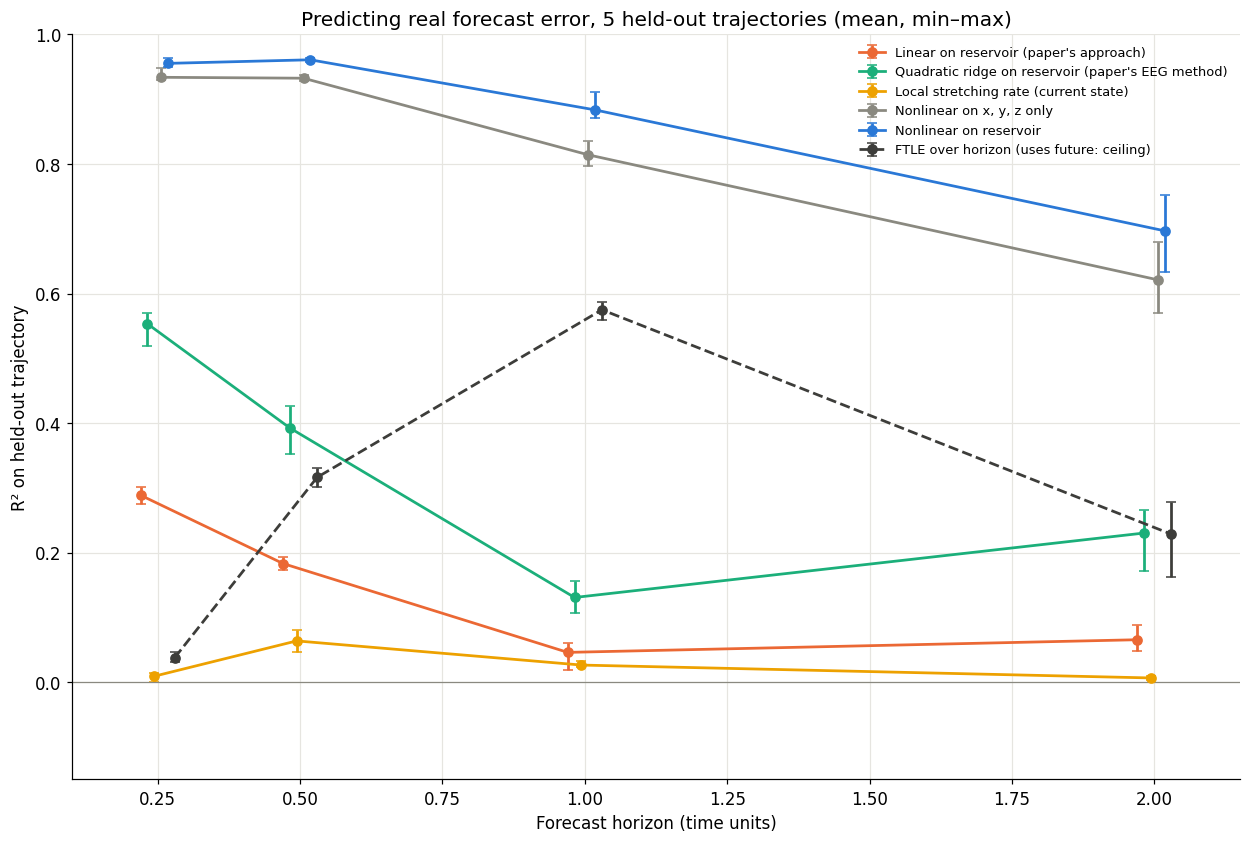

In [52]:
E_colors = {"Linear on reservoir (paper's approach)": ORANGE, "Quadratic ridge on reservoir (paper's EEG method)": AQUA,
            "Local stretching rate (current state)": "#eda100", "Nonlinear on x, y, z only": GREY,
            "Nonlinear on reservoir": BLUE, "FTLE over horizon (uses future: ceiling)": "#3d3d3a"}
fig, ax = plt.subplots(figsize=(11.5, 7.8))
offsets = np.linspace(-0.03, 0.03, len(E_MODELS))
for off, name in zip(offsets, E_MODELS):
    g = E_res[E_res.model == name].groupby("horizon")["R2"]
    xh = np.array(E_HORIZONS)*E_DT + off
    m, lo, hi = g.mean().values, g.min().values, g.max().values
    ls = "--" if "FTLE" in name else "-"
    ax.errorbar(xh, m, yerr=[m - lo, hi - m], fmt="o" + ls, color=E_colors[name], ms=6, lw=1.8, capsize=3, label=name)
ax.axhline(0, color=GREY, lw=0.8); ax.set_ylim(-0.15, 1.0); ax.set_xlim(0.1, 2.15)
ax.set_xlabel("Forecast horizon (time units)"); ax.set_ylabel("R² on held-out trajectory")
ax.set_title("Predicting real forecast error, 5 held-out trajectories (mean, min–max)")
ax.legend(loc="upper right", fontsize=8.5, ncol=1); plt.tight_layout(); plt.show()

### E2. Is the reservoir's advantage consistent? One dot per held-out trajectory
At 1 time unit ahead: each trajectory's R² for every model. The paired differences check whether the reservoir beats position-only on *every* trajectory, not just on average.

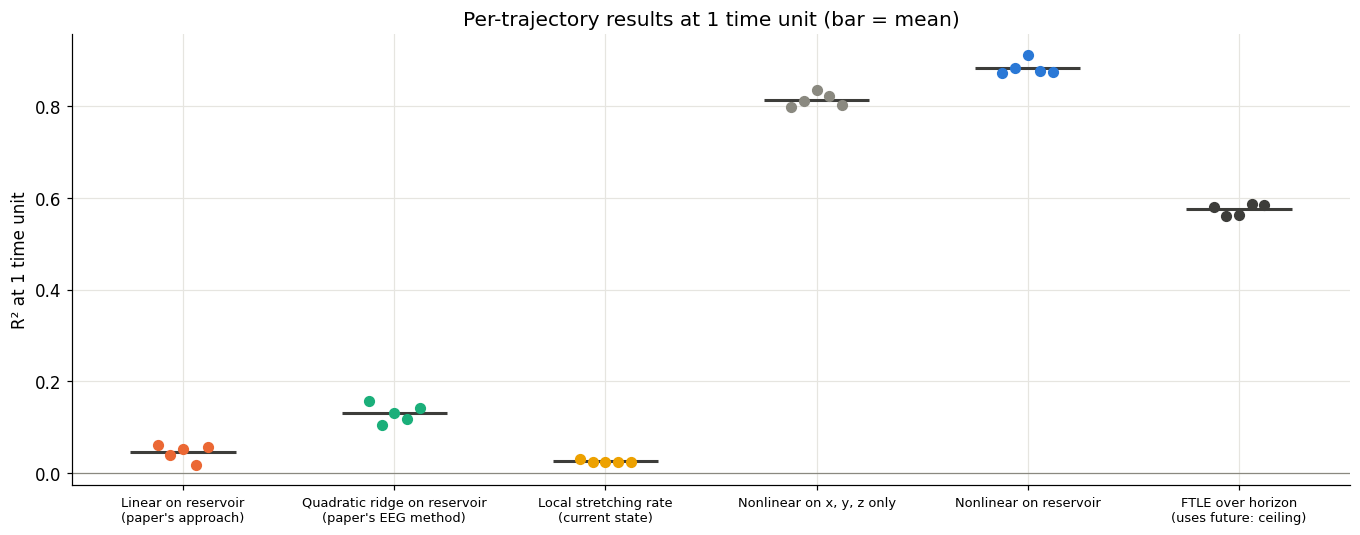

Reservoir minus position-only R², per held-out trajectory: {1: 0.075, 2: 0.071, 3: 0.075, 4: 0.054, 5: 0.072}
Mean 0.069, smallest 0.054; reservoir better on 5 of 5 trajectories
FTLE ceiling minus reservoir estimator: mean -0.309


In [49]:
h = 100
sub = E_res[(E_res.horizon == h) & E_res.R2.notna()]
names = list(E_MODELS)
fig, ax = plt.subplots(figsize=(12.5, 5))
for i, name in enumerate(names):
    v = sub[sub.model == name].sort_values("held-out trajectory")["R2"].values
    ax.scatter(np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), v, s=40, color=E_colors[name], zorder=3)
    ax.hlines(v.mean(), i - 0.25, i + 0.25, color="#3d3d3a", lw=2)
ax.set_xticks(range(len(names)), [n.replace(" (", "\n(") for n in names], fontsize=8.5)
ax.axhline(0, color=GREY, lw=0.8); ax.set_ylabel("R² at 1 time unit")
ax.set_title("Per-trajectory results at 1 time unit (bar = mean)"); plt.tight_layout(); plt.show()

piv = sub.pivot(index="held-out trajectory", columns="model", values="R2")
diff = piv["Nonlinear on reservoir"] - piv["Nonlinear on x, y, z only"]
print("Reservoir minus position-only R², per held-out trajectory:", diff.round(3).to_dict())
print(f"Mean {diff.mean():.3f}, smallest {diff.min():.3f}; reservoir better on {int((diff > 0).sum())} of {len(diff)} trajectories")
gap = piv["FTLE over horizon (uses future: ceiling)"] - piv["Nonlinear on reservoir"]
print(f"FTLE ceiling minus reservoir estimator: mean {gap.mean():.3f}")

### E3. Fig. 5 and Fig. 6 equivalents on a held-out trajectory
Actual forecast error against the nonlinear reservoir estimate, the linear estimate and the FTLE ceiling, on one held-out trajectory. Scatters are pooled over all five held-out trajectories.

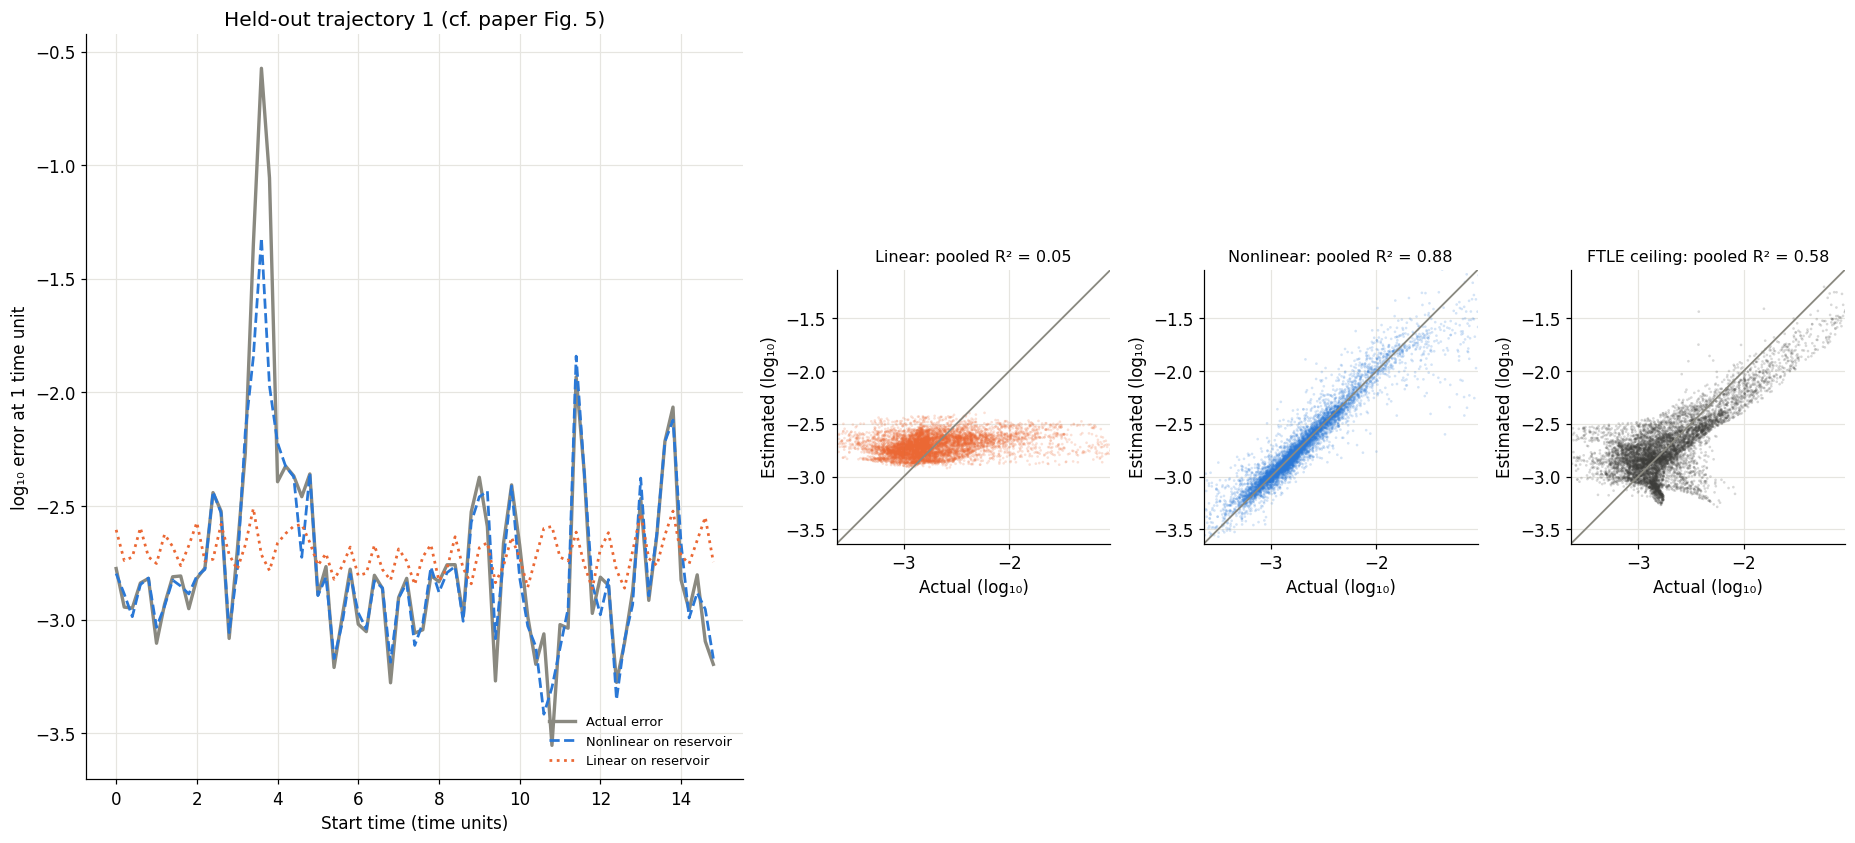

In [54]:
d0 = E_data[0]; tr0 = d0["traj"]; seg = slice(0, 75)    # 75 starts × 20 steps = 15 time units
y0 = d0["y"][h]; t_axis = (d0["starts"][seg] - d0["starts"][0])*E_DT
fig, axes = plt.subplots(1, 4, figsize=(17, 7.8), gridspec_kw={"width_ratios": [2.4, 1, 1, 1]})
axes[0].plot(t_axis, y0[seg], color=GREY, lw=2.2, label="Actual error")
axes[0].plot(t_axis, E_preds[("Nonlinear on reservoir", h, tr0)][seg], "--", color=BLUE, lw=1.8, label="Nonlinear on reservoir")
axes[0].plot(t_axis, E_preds[("Linear on reservoir (paper's approach)", h, tr0)][seg], ":", color=ORANGE, lw=1.8, label="Linear on reservoir")
axes[0].set_xlabel("Start time (time units)"); axes[0].set_ylabel("log₁₀ error at 1 time unit")
axes[0].set_title(f"Held-out trajectory {tr0} (cf. paper Fig. 5)"); axes[0].legend(fontsize=8.5, loc="lower right")

y_all = np.concatenate([d["y"][h] for d in E_data]); lims = np.percentile(y_all, [0.5, 99.5])
for ax, name, col, short in [(axes[1], "Linear on reservoir (paper's approach)", ORANGE, "Linear"),
                             (axes[2], "Nonlinear on reservoir", BLUE, "Nonlinear"),
                             (axes[3], "FTLE over horizon (uses future: ceiling)", "#3d3d3a", "FTLE ceiling")]:
    p_all = np.concatenate([E_preds[(name, h, d["traj"])] for d in E_data])
    ax.scatter(y_all, p_all, s=3, alpha=0.2, color=col, edgecolor="none")
    ax.plot(lims, lims, color=GREY, lw=1.2); ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
    ax.set_xlabel("Actual (log₁₀)"); ax.set_ylabel("Estimated (log₁₀)")
    ax.set_title(f"{short}: pooled R² = {r2_score(y_all, p_all):.2f}", fontsize=10.5)
plt.tight_layout(); plt.show()

### E4. Trust staircase, pooled over held-out trajectories
As C6: forecasts are grouped into tenths by each method's estimate, and the actual median error is plotted per group. Includes the paper's confidence measure (grouped from most to least confident).

C:\Users\B00732999\AppData\Local\Temp\ipykernel_11024\3001961667.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(x, deciles(p_all), "-o", color=col, ms=6, label=name, ls="--" if "FTLE" in name else "-")


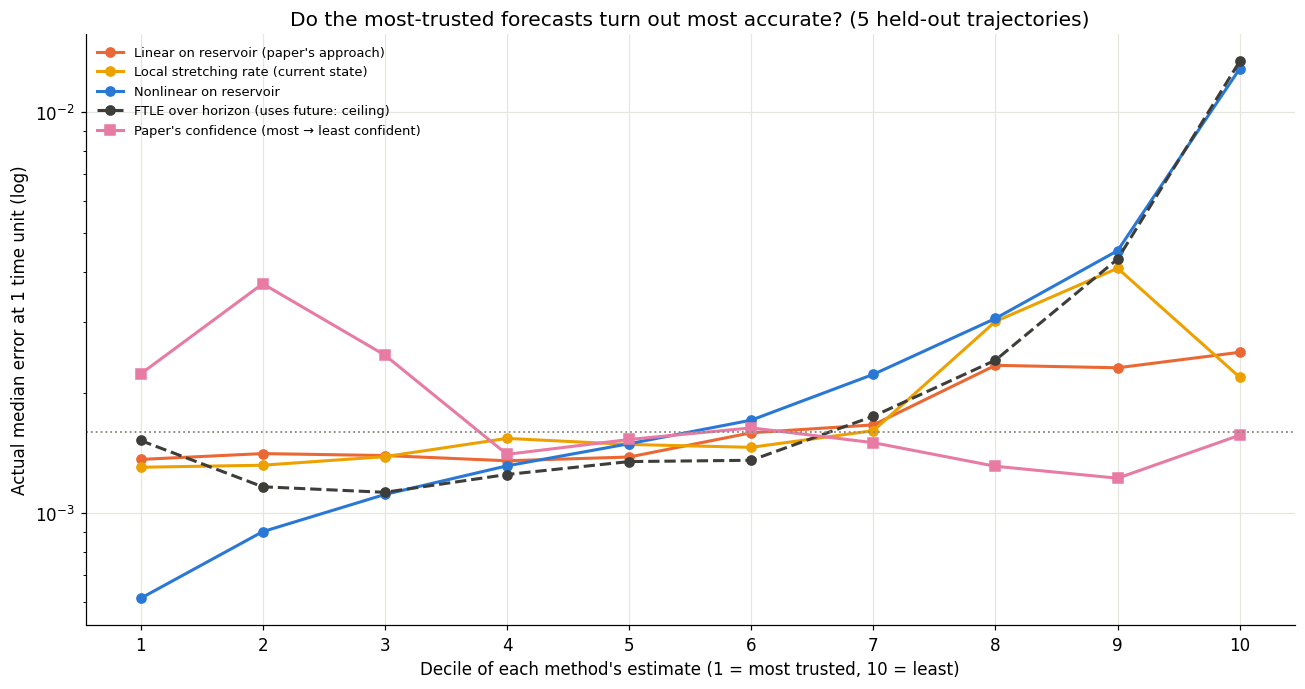

In [57]:
actual_all = 10**y_all
def deciles(score):
    q = pd.qcut(score, 10, labels=False, duplicates="drop")
    return pd.Series(actual_all).groupby(q).median().values
fig, ax = plt.subplots(figsize=(12, 6.4)); x = np.arange(1, 11)
for name, col in [("Linear on reservoir (paper's approach)", ORANGE), ("Local stretching rate (current state)", "#eda100"),
                  ("Nonlinear on reservoir", BLUE), ("FTLE over horizon (uses future: ceiling)", "#3d3d3a")]:
    p_all = np.concatenate([E_preds[(name, h, d["traj"])] for d in E_data])
    ax.plot(x, deciles(p_all), "-o", color=col, ms=6, label=name, ls="--" if "FTLE" in name else "-")
C_all = np.concatenate([d["C_paper"] for d in E_data])
ax.plot(x, deciles(-C_all), "-s", color="#e87ba4", ms=6, label="Paper's confidence (most → least confident)")
ax.axhline(np.median(actual_all), color=GREY, ls=":", lw=1.2)
ax.set_yscale("log"); ax.set_xticks(x)
ax.set_xlabel("Decile of each method's estimate (1 = most trusted, 10 = least)")
ax.set_ylabel("Actual median error at 1 time unit (log)")
ax.set_title("Do the most-trusted forecasts turn out most accurate? (5 held-out trajectories)")
ax.legend(fontsize=8.5, loc="upper left"); plt.tight_layout(); plt.show()

### E5. Tuning and stability checks
Left: how the forecaster's α was chosen, using trajectory 0's own validation segment only. Right: how long free-running forecasts stay accurate on each held-out trajectory. Similar boxes mean the trajectories are comparable.

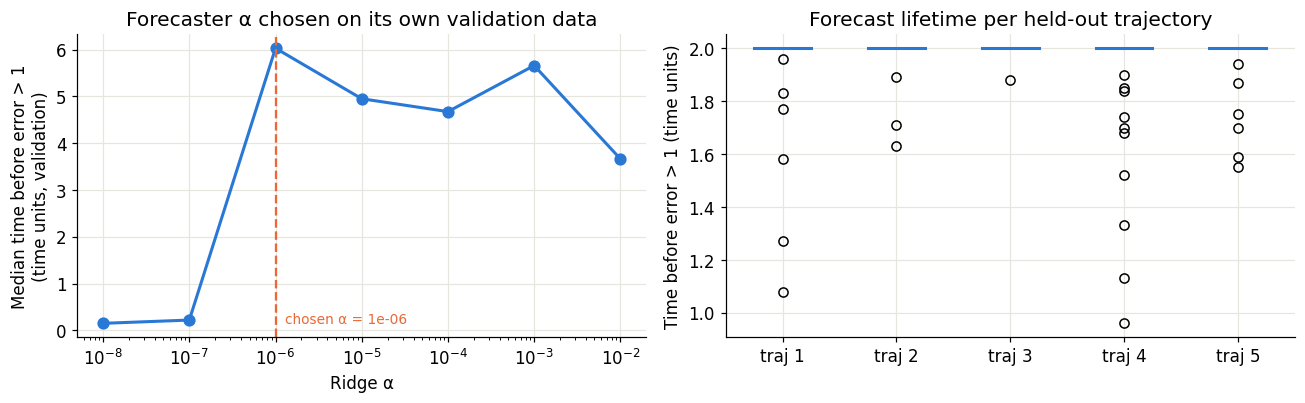

Settings chosen by cross-validation inside the training trajectories (one entry per held-out trajectory, h = 100):


held-out trajectory,1,2,3,4,5
model,,,,,
Linear on reservoir (paper's approach),0.001,0.001,0.001,0.001,0.001
Nonlinear on reservoir,"{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '..."
"Nonlinear on x, y, z only","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...","{'learning_rate': 0.1, 'max_leaf_nodes': 31, '..."
Quadratic ridge on reservoir (paper's EEG method),0.001,0.001,0.001,0.001,0.001


In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogx(alpha_grid, np.array(alpha_scores)*E_DT, "-o", color=BLUE, ms=7)
axes[0].axvline(E_alpha, color=ORANGE, lw=1.5, ls="--"); axes[0].text(E_alpha*1.3, min(alpha_scores)*E_DT, f"chosen α = {E_alpha:g}", color=ORANGE, fontsize=9)
axes[0].set_xlabel("Ridge α"); axes[0].set_ylabel("Median time before error > 1\n(time units, validation)")
axes[0].set_title("Forecaster α chosen on its own validation data")
axes[1].boxplot([d["valid"]*E_DT for d in E_data], patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", color=BLUE), medianprops=dict(color=BLUE, lw=2))
axes[1].set_xticks(range(1, len(E_data) + 1), [f"traj {d['traj']}" for d in E_data])
axes[1].set_ylabel("Time before error > 1 (time units)"); axes[1].set_title("Forecast lifetime per held-out trajectory")
plt.tight_layout(); plt.show()

print("Settings chosen by cross-validation inside the training trajectories (one entry per held-out trajectory, h = 100):")
display(E_res[(E_res.horizon == h) & (E_res.chosen != "None") & (E_res.chosen != "")]
        .pivot(index="model", columns="held-out trajectory", values="chosen"))

### E6. Summary of the robust experiment

In [60]:
def summ(model, metric="R2"):
    v = E_res[(E_res.model == model) & (E_res.horizon == 100)][metric]
    return f"{v.mean():.2f} (range {v.min():.2f} to {v.max():.2f})"
E_summary = pd.DataFrame({
    "R² at 1 time unit": {m: summ(m) for m in E_MODELS},
    "Spearman ρ at 1 time unit": {m: summ(m, "Spearman") for m in ["Paper's confidence (repo method)"] + list(E_MODELS)},
})
display(E_summary)
SUMMARY["E. R² at 1 t.u., nonlinear on reservoir (mean of 5 held-out traj.)"] = E_res[(E_res.model=="Nonlinear on reservoir")&(E_res.horizon==100)].R2.mean()
SUMMARY["E. R² at 1 t.u., linear on reservoir"] = E_res[(E_res.model=="Linear on reservoir (paper's approach)")&(E_res.horizon==100)].R2.mean()
SUMMARY["E. R² at 1 t.u., FTLE ceiling"] = E_res[(E_res.model=="FTLE over horizon (uses future: ceiling)")&(E_res.horizon==100)].R2.mean()
SUMMARY["E. Spearman ρ at 1 t.u., paper's confidence (−C)"] = E_res[(E_res.model=="Paper's confidence (repo method)")&(E_res.horizon==100)].Spearman.mean()

,R² at 1 time unit,Spearman ρ at 1 time unit
Linear on reservoir (paper's approach),0.05 (range 0.02 to 0.06),0.27 (range 0.23 to 0.29)
Quadratic ridge on reservoir (paper's EEG method),0.13 (range 0.11 to 0.16),0.37 (range 0.35 to 0.39)
Local stretching rate (current state),0.03 (range 0.02 to 0.03),0.25 (range 0.24 to 0.26)
"Nonlinear on x, y, z only",0.81 (range 0.80 to 0.84),0.93 (range 0.91 to 0.94)
Nonlinear on reservoir,0.88 (range 0.87 to 0.91),0.96 (range 0.96 to 0.97)
FTLE over horizon (uses future: ceiling),0.57 (range 0.56 to 0.59),0.55 (range 0.54 to 0.56)
Paper's confidence (repo method),NaN,-0.23 (range -0.24 to -0.21)


In [61]:
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
display(pd.DataFrame({"Value": SUMMARY}))

,Value
"A. Ablation R², full reservoir (unreported)",1
A. Original estimator R² (paper: 0.9988),0.9903
A. Ridge vs linear t-statistic (paper: 9.46),3.082
B. 'Same as last step' baseline R²,0.9886
B. Condition number,7.547e+15
"B. Effective sample size (of 2,000 test points)",189.1
"B. Estimator R², stable readout",0.278
"B. Mean error, repo solver",0.1038
"B. Mean error, stable solver",1.121e-05
C. R² at 1 time unit: Linear on reservoir (paper's approach),0.06339
